# TP - CIENCIA DE DATOS

## Carga de Datos y Librerias

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

ruta = '/content/drive/MyDrive/TpCienciaDatos/'

#df_vuelos = pd.read_csv(ruta + 'Vuelos.csv', sep=';', encoding='utf-8-sig')
#df_clientes = pd.read_csv(ruta + 'Clientes.csv', sep=';', encoding='utf-8-sig')
#df_vuelos_nuevos = pd.read_csv(ruta + 'casosNuevos.csv', sep=';', encoding='utf-8-sig')
#df_relacion = pd.read_csv(ruta + 'casosNuevos_Clientes.csv', sep=';', encoding='utf-8-sig')

df_vuelos = pd.read_csv(ruta + 'Vuelos.csv', sep=';', encoding='latin1')
df_clientes = pd.read_csv(ruta + 'Clientes.csv', sep=';', encoding='latin1')
df_vuelos_nuevos = pd.read_csv(ruta + 'casosNuevos.csv', sep=';', encoding='latin1')
df_relacion = pd.read_csv(ruta + 'casosNuevos_Clientes.csv', sep=';', encoding='latin1')

df_vuelos['ocupacion_vuelo'] = (
    df_vuelos['ocupacion_vuelo']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

df_vuelos_nuevos['ocupacion_vuelo'] = (
    df_vuelos_nuevos['ocupacion_vuelo']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

df_vuelos['visibilidad'] = (
    df_vuelos['visibilidad']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

df_vuelos_nuevos['visibilidad'] = (
    df_vuelos_nuevos['visibilidad']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)
from google.colab import drive
drive.mount('/content/drive')
# VERSION ANTERIOR (tenia error en el argumento de los parametros encoding y con los metodos astype,
# sino funciona el codigo actual, usar el codigo anterior, puede deberse a un error en mi pc)
# import pandas as pd

# import numpy as np
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.model_selection import train_test_split
# from sklearn.preprocessing import StandardScaler, LabelEncoder

# ruta = '/content/drive/MyDrive/TpCienciaDatos/'

# df_vuelos = pd.read_csv(ruta + 'Vuelos.csv', sep=';', encoding='latin1')
# df_clientes = pd.read_csv(ruta + 'Clientes.csv', sep=';', encoding='latin1')
# df_vuelos_nuevos = pd.read_csv(ruta + 'casosNuevos.csv', sep=';', encoding='latin1')
# df_relacion = pd.read_csv(ruta + 'casosNuevos_Clientes.csv', sep=';', encoding='latin1')

# df_vuelos['ocupacion_vuelo'] = (
#     df_vuelos['ocupacion_vuelo']
#     .str.replace(',', '.')
#     .astype(float)
# )

# df_vuelos_nuevos['ocupacion_vuelo'] = (
#     df_vuelos_nuevos['ocupacion_vuelo']
#     .str.replace(',', '.')
#     .astype(float)
# )

# df_vuelos['visibilidad'] = (
#     df_vuelos['visibilidad']
#     .str.replace(',', '.')
#     .astype(float)
# )

# df_vuelos_nuevos['visibilidad'] = (
#     df_vuelos_nuevos['visibilidad']
#    .str.replace(',', '.')
#     .astype(float)
# )

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# ver correlaciones en clientes

In [ ]:
df_clientes.select_dtypes(include=['int64','float64']).columns
corr = df_clientes.select_dtypes(include=['int64','float64']).corr()

corr

,id_cliente,edad,cant_vuelos,cantidad_millas,ingreso_mensual,anticipacion_compra_promedio
id_cliente,1.000000,-0.002166,-0.002296,-0.002445,-0.002616,0.001688
edad,-0.002166,1.000000,0.110337,0.037856,0.085945,-0.079897
cant_vuelos,-0.002296,0.110337,1.000000,0.496919,0.319427,-0.112958
cantidad_millas,-0.002445,0.037856,0.496919,1.000000,0.263447,-0.058110
ingreso_mensual,-0.002616,0.085945,0.319427,0.263447,1.000000,-0.053490
anticipacion_compra_promedio,0.001688,-0.079897,-0.112958,-0.058110,-0.053490,1.000000


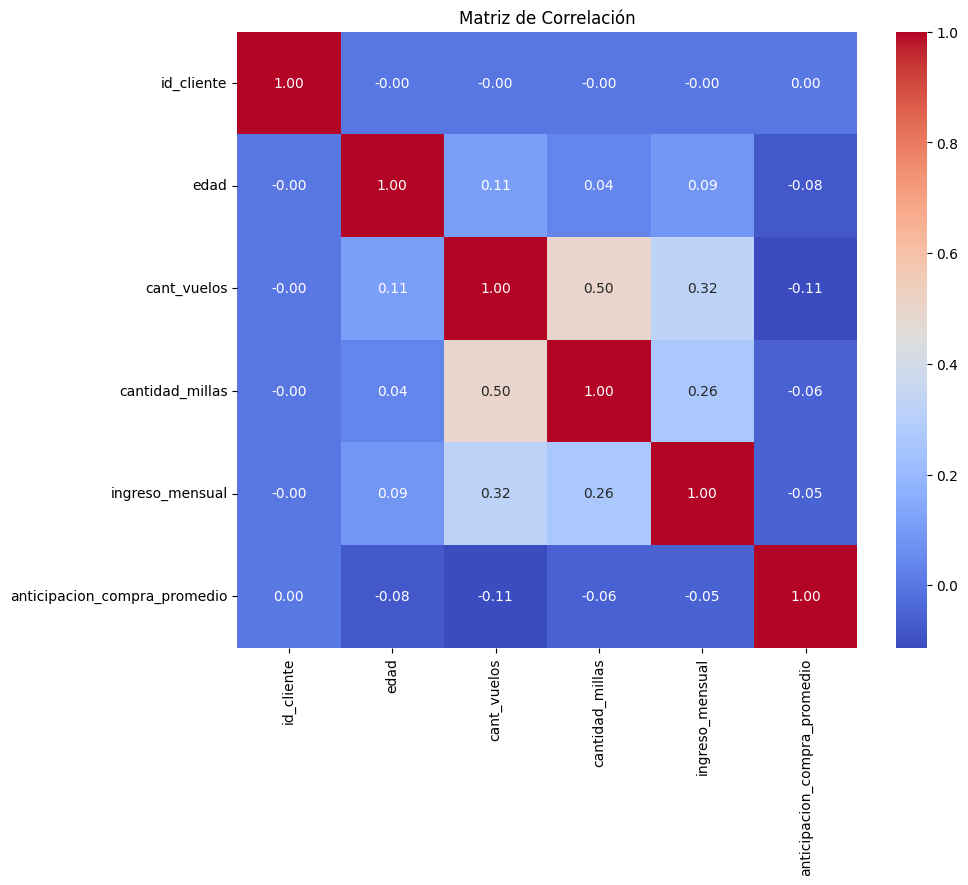

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlación')
plt.show()

In [ ]:
corr = df_clientes.select_dtypes(include=['int64','float64']).corr()

for i in corr.columns:
    for j in corr.columns:
        if i != j:
            if abs(corr.loc[i,j]) > 0.45:
                print(i, "<->", j, "=", round(corr.loc[i,j],3))

cant_vuelos <-> cantidad_millas = 0.497
cantidad_millas <-> cant_vuelos = 0.497


## Fase 2: Entendimiento de los Datos

### 2.1. Calidad de Datos y Estructura

In [ ]:
print("Estructura de Vuelos:", df_vuelos.shape)
print("\n--- Tipos de datos y Nulos ---")
df_vuelos.info()
df_vuelos_nuevos.info()

nulos = df_vuelos.isnull().sum()
if nulos.sum() > 0:
    print("\n¡Atención! Se encontraron nulos en:")
    print(nulos[nulos > 0])
else:
    print("\nNo se detectaron valores nulos en el dataset de vuelos.")

Estructura de Vuelos: (15000, 15)

--- Tipos de datos y Nulos ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_vuelo                15000 non-null  int64  
 1   aeropuerto_origen       15000 non-null  object 
 2   aeropuerto_destino      15000 non-null  object 
 3   hora_salida_programada  15000 non-null  object 
 4   dia_semana              15000 non-null  object 
 5   distancia_vuelo         15000 non-null  int64  
 6   condiciones_climaticas  15000 non-null  object 
 7   congestion_aerea        15000 non-null  object 
 8   tipo_avion              15000 non-null  object 
 9   ocupacion_vuelo         15000 non-null  float64
 10  temporada_alta          15000 non-null  object 
 11  puerta_embarque         15000 non-null  int64  
 12  visibilidad             15000 non-null  float64
 13  tiempo_estimado_vuelo   1

###2.2. preparacion inicial de datos

In [ ]:
# ocupacion_vuelo
df_vuelos['ocupacion_vuelo'] = (
    df_vuelos['ocupacion_vuelo']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

df_vuelos_nuevos['ocupacion_vuelo'] = (
    df_vuelos_nuevos['ocupacion_vuelo']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

# visibilidad
df_vuelos['visibilidad'] = (
    df_vuelos['visibilidad']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

df_vuelos_nuevos['visibilidad'] = (
    df_vuelos_nuevos['visibilidad']
    .astype(str)
    .str.replace(',', '.')
    .astype(float)
)

# hora_salida_programada
df_vuelos['hora_salida_programada'] = (
    df_vuelos['hora_salida_programada']
    .str.split(':')
    .str[0]
    .astype(int)
)

df_vuelos_nuevos['hora_salida_programada'] = (
    df_vuelos_nuevos['hora_salida_programada']
    .str.split(':')
    .str[0]
    .astype(int)
)

###2.3. analisis univariado

####2.3.1.  vars categoricas


VARIABLE: aeropuerto_origen

Frecuencia absoluta:
aeropuerto_origen
EZE    2132
BOG    1937
MDE    1565
GRU    1447
PTY    1333
LIM     411
UIO     380
PEI     368
MIA     349
BAQ     339
CTG     339
CLO     297
CCS     290
AEP     283
JFK     280
BGA     276
MVD     240
MEX     213
GIG     210
SCL     194
ROS     156
MAD     153
CWB     131
POA     129
COR     129
FLN     127
SJO     121
NQN     116
ASU     112
MDZ     107
IGR     106
BSB     105
BRC      97
GUA      96
TUC      94
IAH      83
CLT      80
SSA      71
AMS      53
CDG      51
Name: count, dtype: int64

Frecuencia relativa (%):
aeropuerto_origen
EZE    14.21
BOG    12.91
MDE    10.43
GRU     9.65
PTY     8.89
LIM     2.74
UIO     2.53
PEI     2.45
MIA     2.33
BAQ     2.26
CTG     2.26
CLO     1.98
CCS     1.93
AEP     1.89
JFK     1.87
BGA     1.84
MVD     1.60
MEX     1.42
GIG     1.40
SCL     1.29
ROS     1.04
MAD     1.02
CWB     0.87
POA     0.86
COR     0.86
FLN     0.85
SJO     0.81
NQN     0.77
ASU     0.75
MDZ 

/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


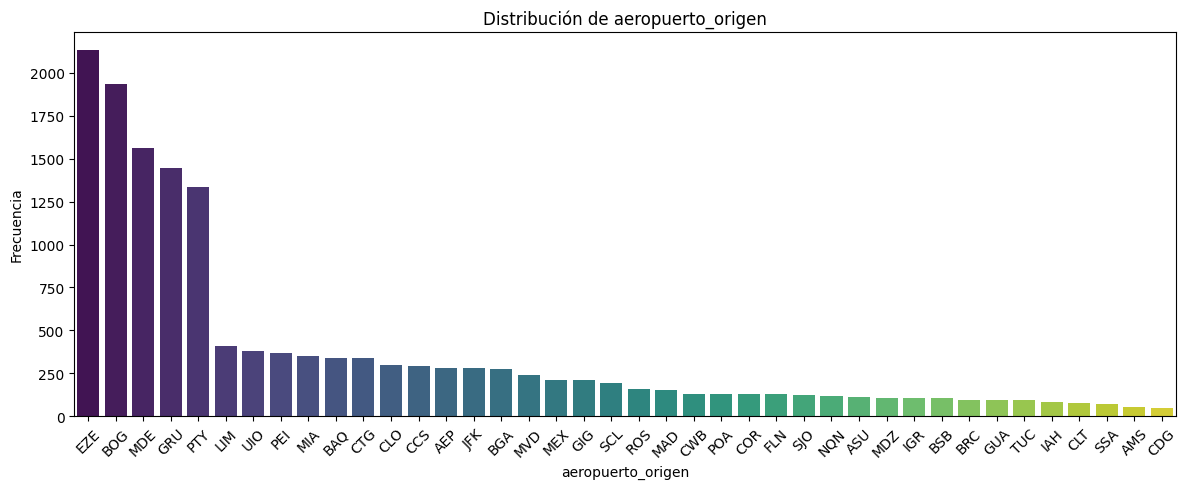


VARIABLE: aeropuerto_destino

Frecuencia absoluta:
aeropuerto_destino
EZE    2196
BOG    1827
GRU    1511
MDE    1410
PTY    1259
UIO     429
LIM     405
MIA     363
CTG     355
PEI     349
BGA     341
BAQ     334
JFK     331
CLO     327
CCS     282
AEP     279
MVD     271
MEX     205
GIG     204
SCL     188
MAD     169
ROS     146
GUA     143
SJO     133
FLN     122
CWB     122
COR     116
BRC     114
IGR     113
MDZ     108
BSB     104
TUC     102
ASU     101
POA      99
NQN      91
CLT      85
SSA      79
IAH      79
AMS      57
CDG      51
Name: count, dtype: int64

Frecuencia relativa (%):
aeropuerto_destino
EZE    14.64
BOG    12.18
GRU    10.07
MDE     9.40
PTY     8.39
UIO     2.86
LIM     2.70
MIA     2.42
CTG     2.37
PEI     2.33
BGA     2.27
BAQ     2.23
JFK     2.21
CLO     2.18
CCS     1.88
AEP     1.86
MVD     1.81
MEX     1.37
GIG     1.36
SCL     1.25
MAD     1.13
ROS     0.97
GUA     0.95
SJO     0.89
FLN     0.81
CWB     0.81
COR     0.77
BRC     0.76
IGR     0.75
M

/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


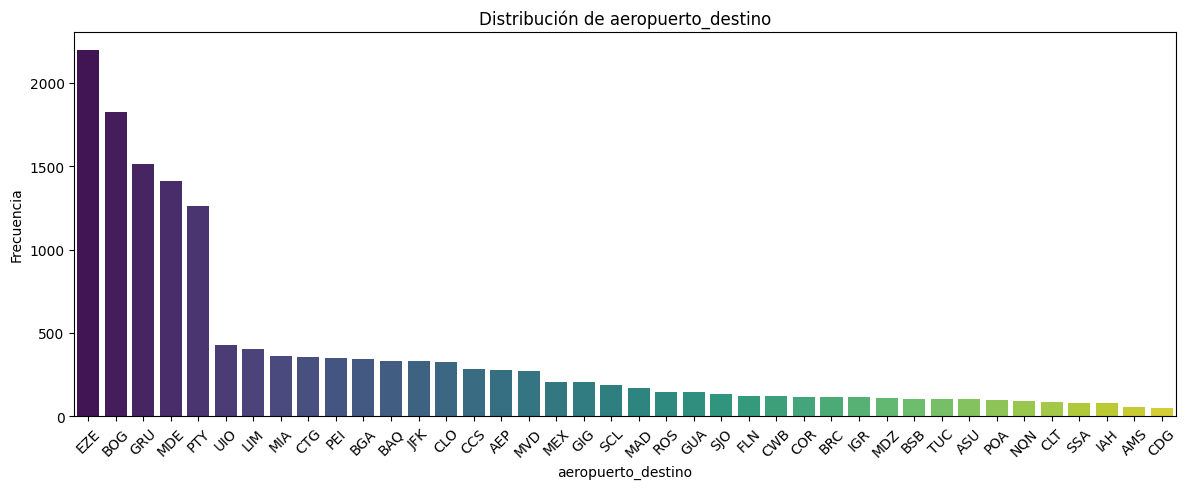


VARIABLE: dia_semana

Frecuencia absoluta:
dia_semana
Viernes      2385
Domingo      2263
Sábado       2243
Miércoles    2149
Jueves       2036
Lunes        1978
Martes       1946
Name: count, dtype: int64

Frecuencia relativa (%):
dia_semana
Viernes      15.90
Domingo      15.09
Sábado       14.95
Miércoles    14.33
Jueves       13.57
Lunes        13.19
Martes       12.97
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


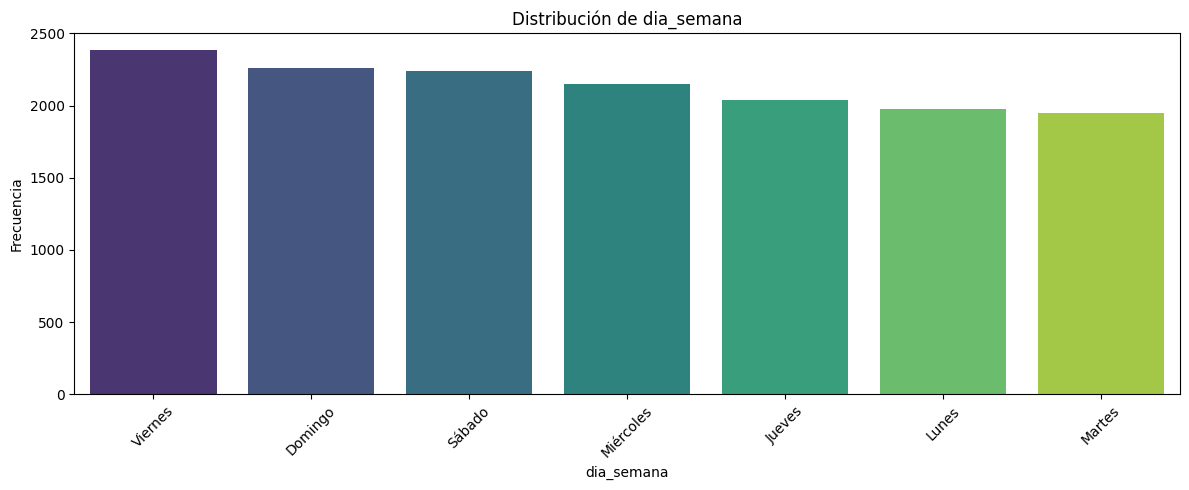


VARIABLE: condiciones_climaticas

Frecuencia absoluta:
condiciones_climaticas
Despejado    6761
Nublado      3737
Lluvia       2267
Tormenta     1175
Niebla       1060
Name: count, dtype: int64

Frecuencia relativa (%):
condiciones_climaticas
Despejado    45.07
Nublado      24.91
Lluvia       15.11
Tormenta      7.83
Niebla        7.07
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


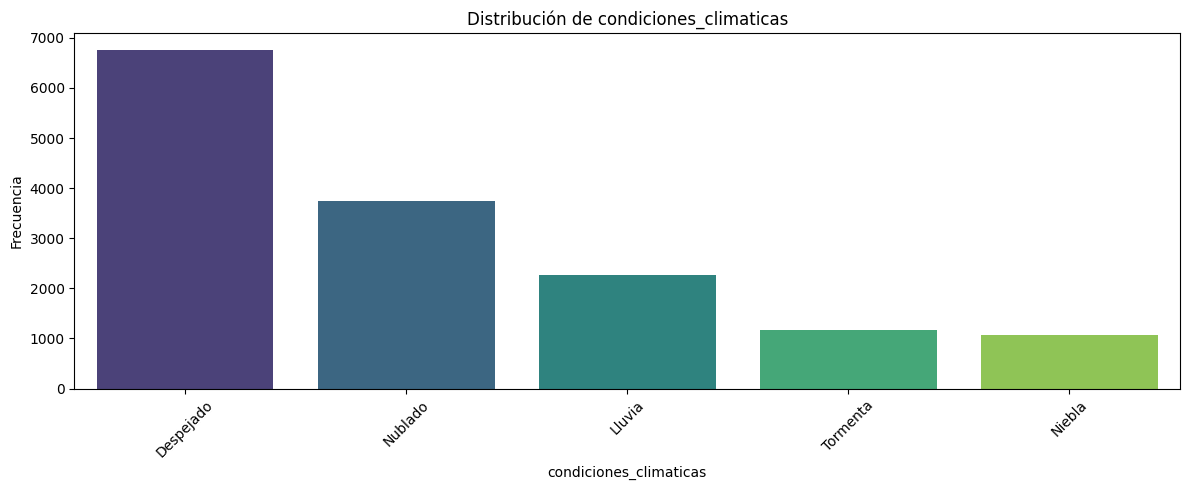


VARIABLE: congestion_aerea

Frecuencia absoluta:
congestion_aerea
Baja     6029
Media    5978
Alta     2993
Name: count, dtype: int64

Frecuencia relativa (%):
congestion_aerea
Baja     40.19
Media    39.85
Alta     19.95
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


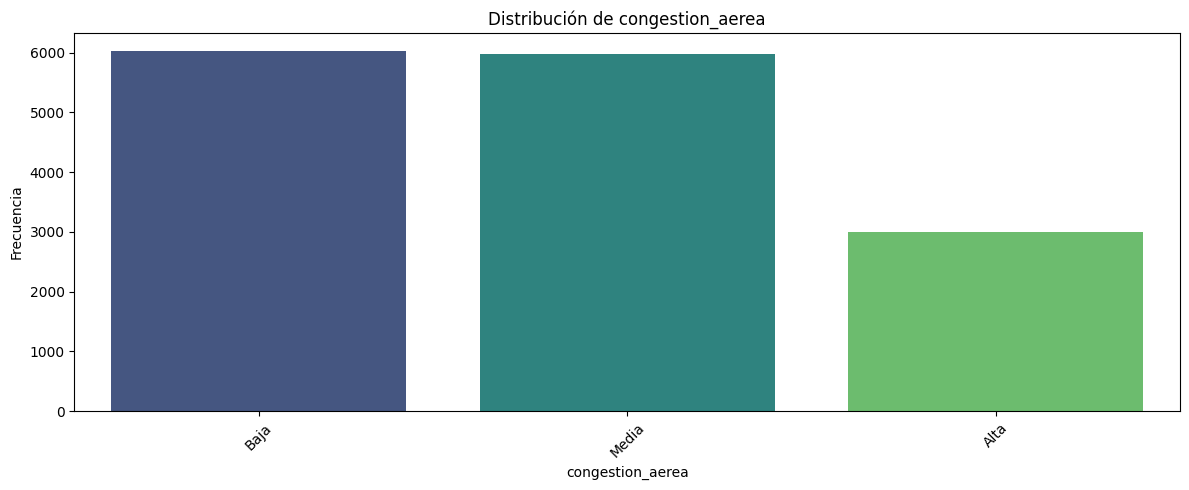


VARIABLE: tipo_avion

Frecuencia absoluta:
tipo_avion
ATR 72            1760
Boeing 737        1710
Embraer E190      1708
Airbus A320       1664
Boeing 757        1352
Airbus A320neo    1352
Embraer E195      1323
Boeing 737 MAX    1294
Boeing 777         775
Airbus A330        712
Airbus A350        704
Boeing 787         646
Name: count, dtype: int64

Frecuencia relativa (%):
tipo_avion
ATR 72            11.73
Boeing 737        11.40
Embraer E190      11.39
Airbus A320       11.09
Boeing 757         9.01
Airbus A320neo     9.01
Embraer E195       8.82
Boeing 737 MAX     8.63
Boeing 777         5.17
Airbus A330        4.75
Airbus A350        4.69
Boeing 787         4.31
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


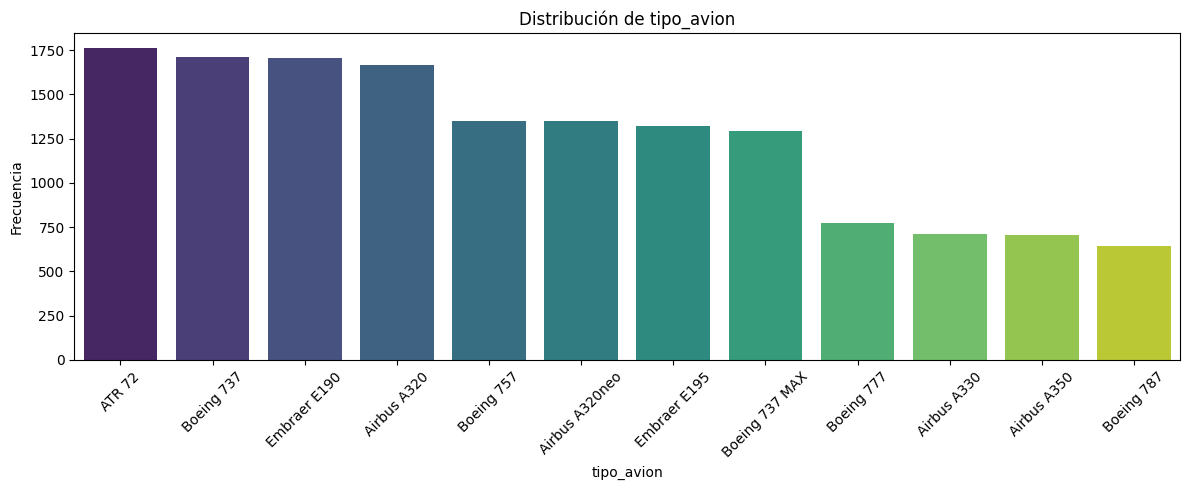


VARIABLE: temporada_alta

Frecuencia absoluta:
temporada_alta
FALSO        9643
VERDADERO    5357
Name: count, dtype: int64

Frecuencia relativa (%):
temporada_alta
FALSO        64.29
VERDADERO    35.71
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


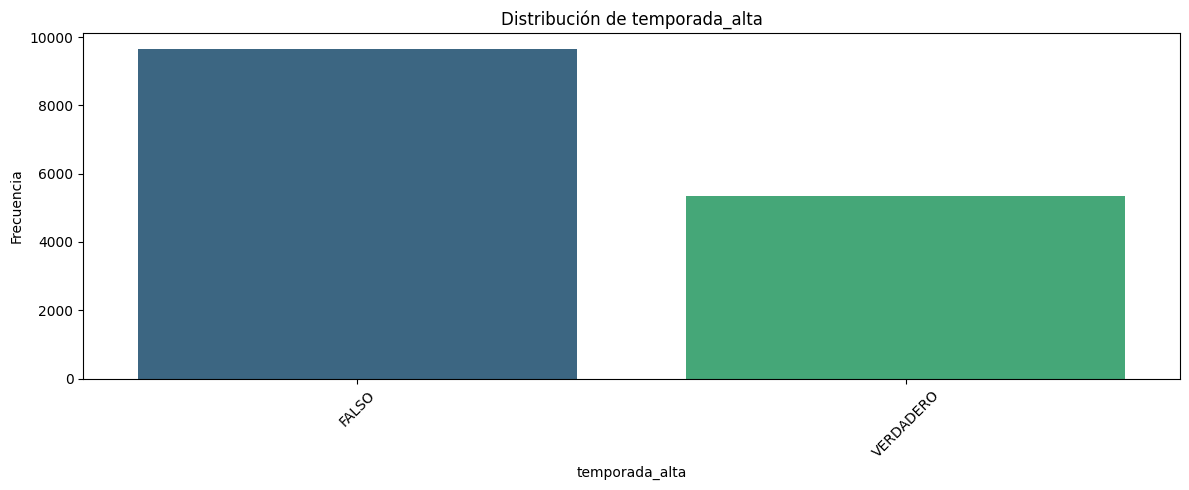


VARIABLE: demora

Frecuencia absoluta:
demora
0    10222
1     4778
Name: count, dtype: int64

Frecuencia relativa (%):
demora
0    68.15
1    31.85
Name: proportion, dtype: float64


/tmp/ipykernel_892/3400377497.py:38: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


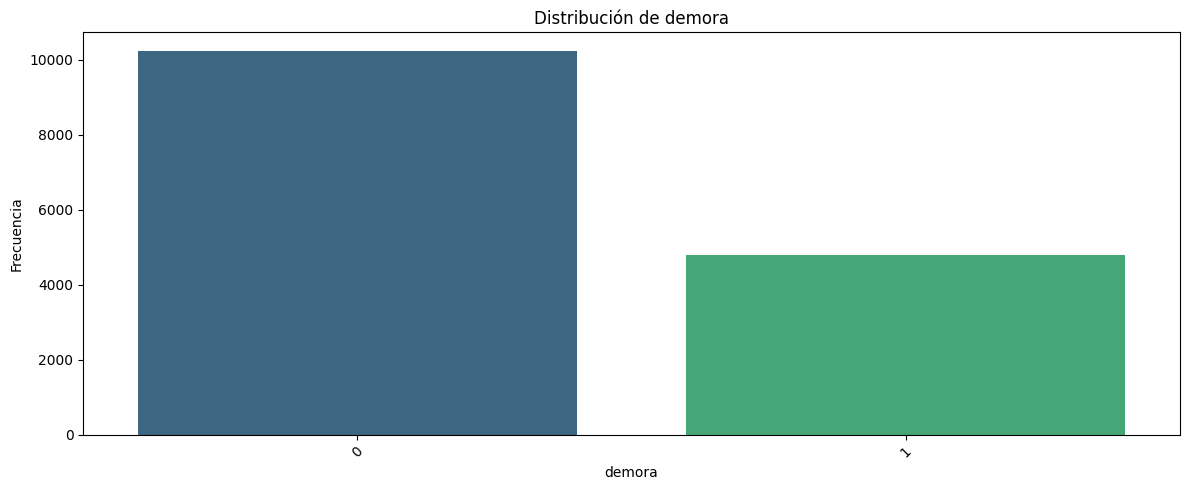

In [ ]:
# ==========================================================
# 2.3.1 VARIABLES CATEGÓRICAS
# ==========================================================

vars_categoricas = [
    'aeropuerto_origen',
    'aeropuerto_destino',
    'dia_semana',
    'condiciones_climaticas',
    'congestion_aerea',
    'tipo_avion',
    'temporada_alta',
    'demora'
]

for var in vars_categoricas:

    print("\n================================================")
    print(f"VARIABLE: {var}")
    print("================================================")

    # Frecuencia absoluta
    print("\nFrecuencia absoluta:")
    print(df_vuelos[var].value_counts())

    # Frecuencia relativa
    print("\nFrecuencia relativa (%):")
    print(
        round(
            df_vuelos[var].value_counts(normalize=True) * 100,
            2
        )
    )

    # Gráfico de barras
    plt.figure(figsize=(12,5))

    sns.countplot(
        data=df_vuelos,
        x=var,
        order=df_vuelos[var].value_counts().index,
        palette='viridis'
    )

    plt.title(f'Distribución de {var}')
    plt.xlabel(var)
    plt.ylabel('Frecuencia')

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

####2.3.2. vars numericas


ANÁLISIS VARIABLE NUMÉRICA: hora_salida_programada

Estadísticos descriptivos:
count    15000.000000
mean        10.974933
std          4.942543
min          0.000000
25%          7.000000
50%         11.000000
75%         15.000000
max         22.000000
Name: hora_salida_programada, dtype: float64
Asimetría (Skewness): 0.06


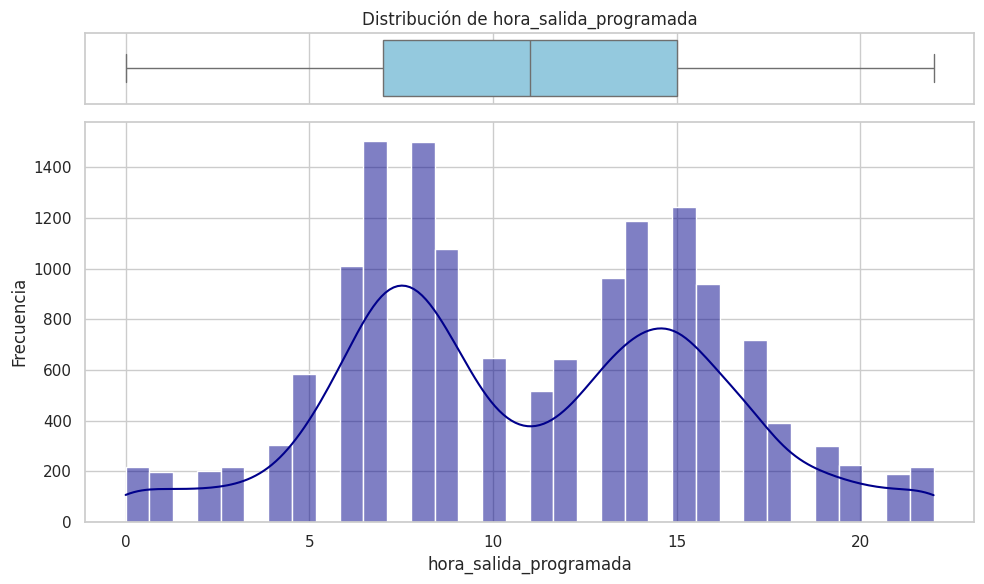


ANÁLISIS VARIABLE NUMÉRICA: distancia_vuelo

Estadísticos descriptivos:
count    15000.000000
mean      1811.709667
std       2276.650883
min         35.000000
25%        300.000000
50%        960.000000
75%       2620.000000
max      10050.000000
Name: distancia_vuelo, dtype: float64
Asimetría (Skewness): 2.02


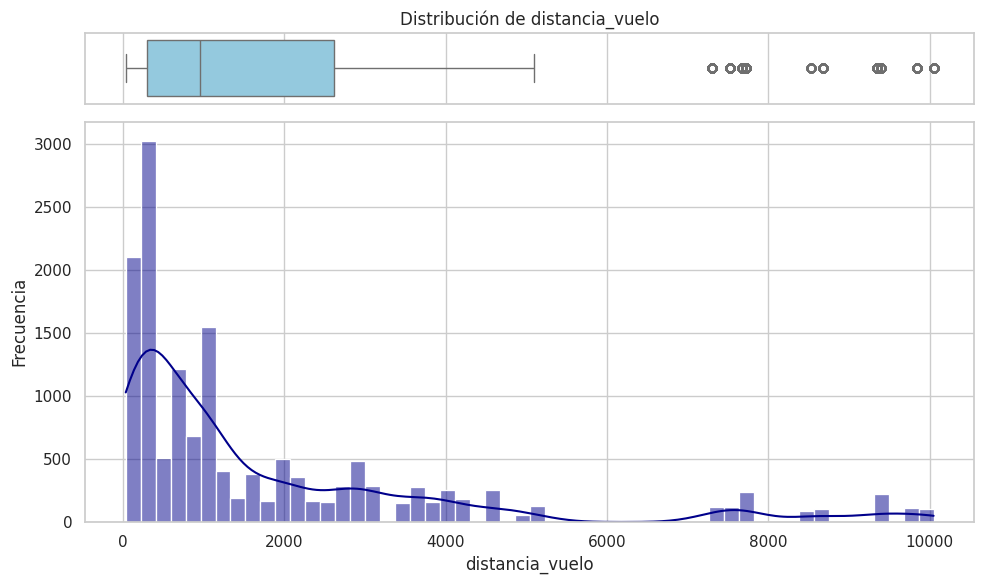


ANÁLISIS VARIABLE NUMÉRICA: ocupacion_vuelo

Estadísticos descriptivos:
count    15000.000000
mean        71.383327
std         15.964749
min          9.200000
25%         61.100000
50%         73.400000
75%         83.800000
max         99.800000
Name: ocupacion_vuelo, dtype: float64
Asimetría (Skewness): -0.60


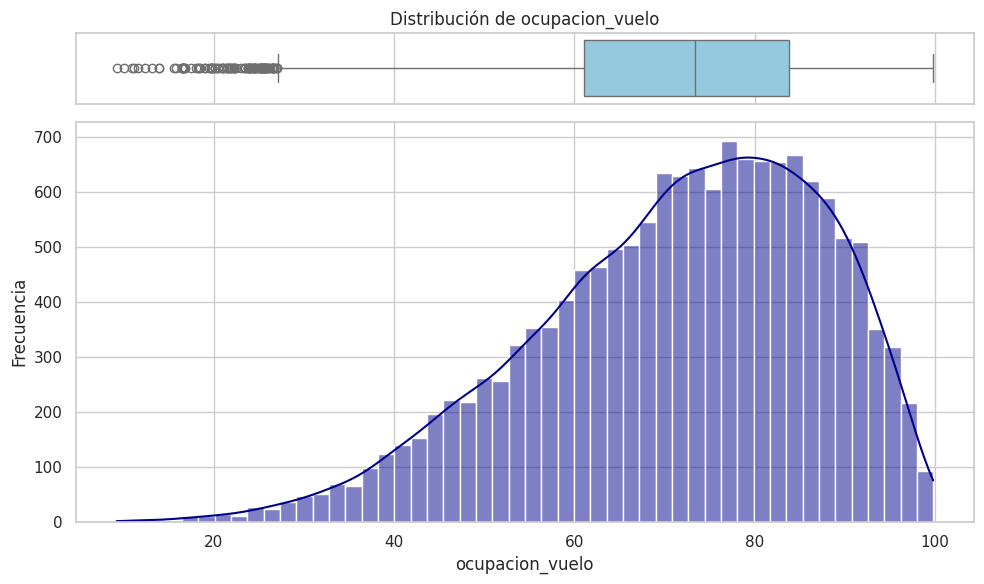


ANÁLISIS VARIABLE NUMÉRICA: puerta_embarque

Estadísticos descriptivos:
count    15000.000000
mean        25.052200
std         14.130638
min          1.000000
25%         13.000000
50%         25.000000
75%         37.000000
max         49.000000
Name: puerta_embarque, dtype: float64
Asimetría (Skewness): -0.01


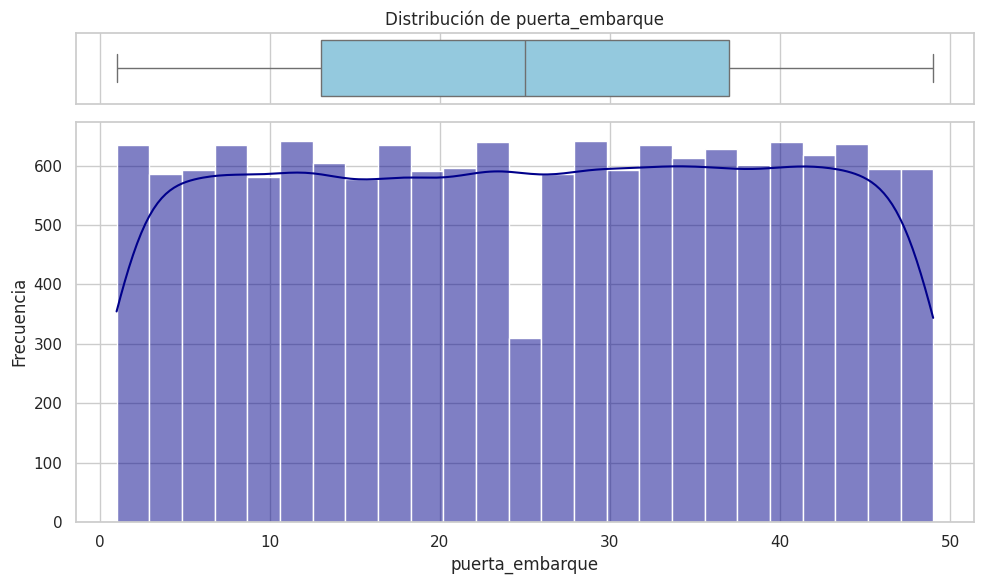


ANÁLISIS VARIABLE NUMÉRICA: visibilidad

Estadísticos descriptivos:
count    15000.000000
mean        15.371927
std          8.633404
min          0.200000
25%          8.100000
50%         15.600000
75%         22.900000
max         30.000000
Name: visibilidad, dtype: float64
Asimetría (Skewness): -0.06


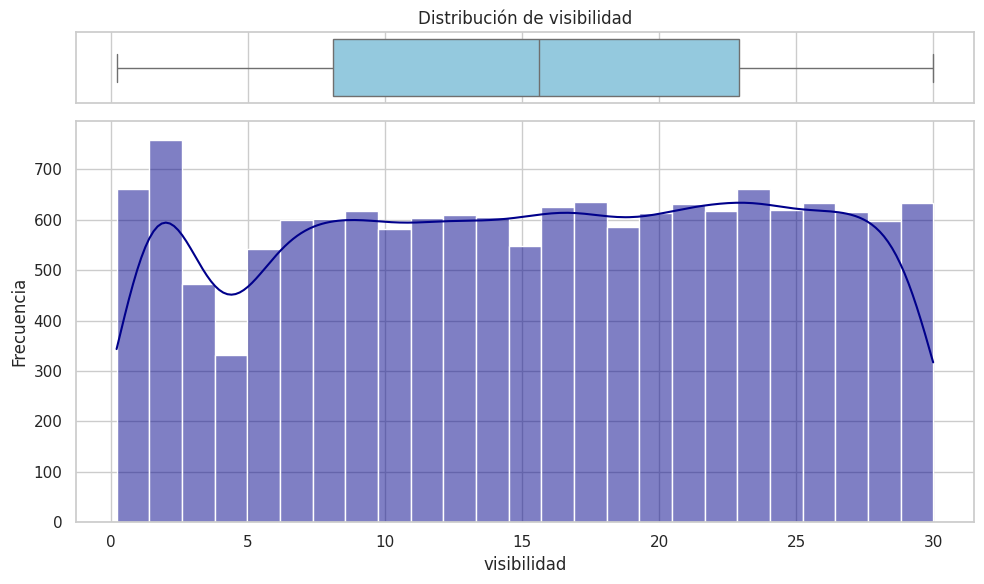


ANÁLISIS VARIABLE NUMÉRICA: tiempo_estimado_vuelo

Estadísticos descriptivos:
count    15000.000000
mean       169.874467
std        171.010583
min         22.000000
25%         58.000000
50%        103.000000
75%        220.000000
max        802.000000
Name: tiempo_estimado_vuelo, dtype: float64
Asimetría (Skewness): 2.01


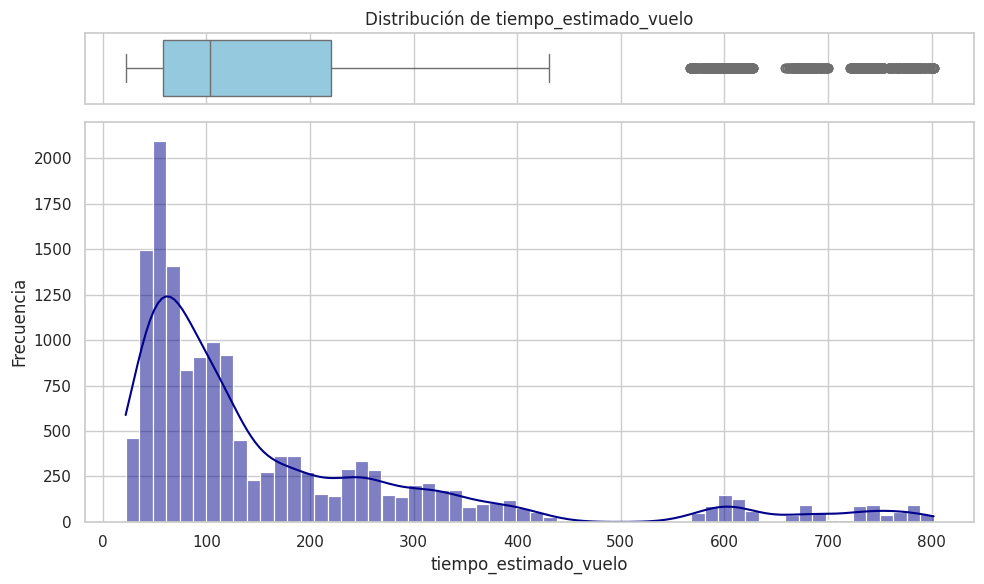

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

vars_numericas = [
    'hora_salida_programada',
    'distancia_vuelo',
    'ocupacion_vuelo',
    'puerta_embarque',
    'visibilidad',
    'tiempo_estimado_vuelo'
]

for var in vars_numericas:
    print("\n================================================")
    print(f"ANÁLISIS VARIABLE NUMÉRICA: {var}")
    print("================================================")

    # 1. ESTADÍSTICOS (Lo que pidió la profe)
    print("\nEstadísticos descriptivos:")
    print(df_vuelos[var].describe())
    print(f"Asimetría (Skewness): {skew(df_vuelos[var].dropna()):.2f}")

    # 2. GRÁFICOS (Histograma + Boxplot en la misma imagen)
    # Creamos una figura con dos subgráficos (uno arriba del otro)
    f, (ax_box, ax_hist) = plt.subplots(2, sharex=True,
                                        gridspec_kw={"height_ratios": (.15, .85)},
                                        figsize=(10, 6))

    # Boxplot
    sns.boxplot(x=df_vuelos[var], ax=ax_box, color="skyblue")
    ax_box.set(title=f'Distribución de {var}', xlabel='')

    # Histograma
    sns.histplot(df_vuelos[var], ax=ax_hist, kde=True, color="darkblue")
    ax_hist.set(xlabel=var, ylabel='Frecuencia')

    plt.tight_layout()
    plt.show()

### 2.2. Análisis de la Variable Objetivo (Demora)

/tmp/ipykernel_3398/670305207.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_vuelos, x='demora', palette='magma')


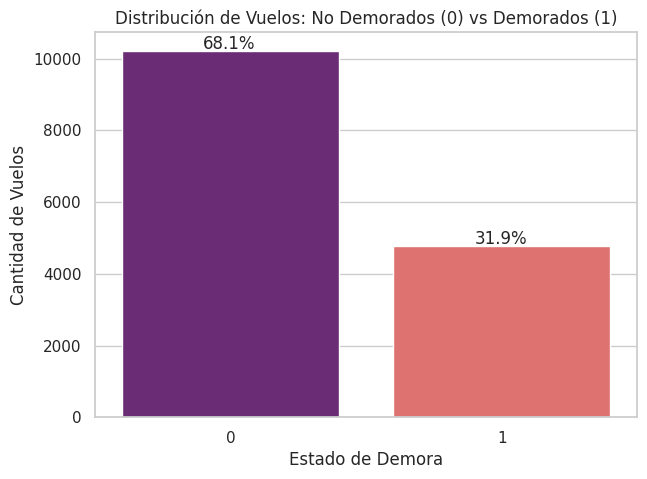

Frecuencia absoluta:
demora
0    10222
1     4778
Name: count, dtype: int64

Frecuencia relativa (%):
demora
0    68.15
1    31.85
Name: proportion, dtype: float64


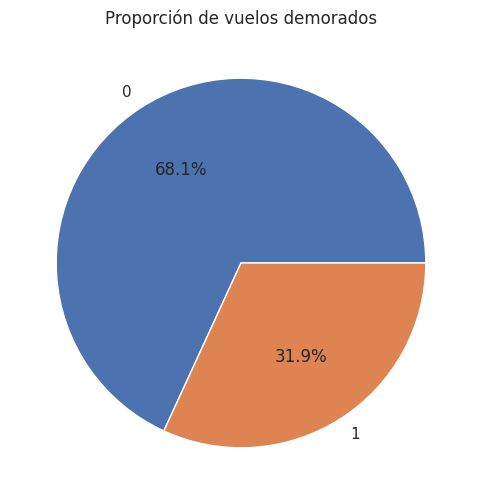

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(7, 5))
ax = sns.countplot(data=df_vuelos, x='demora', palette='magma')
plt.title('Distribución de Vuelos: No Demorados (0) vs Demorados (1)')
plt.xlabel('Estado de Demora')
plt.ylabel('Cantidad de Vuelos')

for p in ax.patches:
    percentage = '{:.1f}%'.format(100 * p.get_height()/len(df_vuelos))
    ax.annotate(percentage, (p.get_x() + 0.3, p.get_height() + 50))

plt.show()
print("Frecuencia absoluta:")
print(df_vuelos['demora'].value_counts())

print("\nFrecuencia relativa (%):")
print(round(df_vuelos['demora'].value_counts(normalize=True)*100,2))
plt.figure(figsize=(6,6))

df_vuelos['demora'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Proporción de vuelos demorados')
plt.ylabel('')

plt.show()

### 2.4. Análisis Multivariante

#### 2.4.1 Relación entre Variables Numéricas y Demora

=== ANÁLISIS ESTADÍSTICO NUMÉRICO SEGÚN DEMORA ===

Estadísticos de 'hora_salida_programada' agrupados por Demora:
         mean  median   std
demora                     
0       10.93    10.0  4.95
1       11.07    11.0  4.92
Diferencia porcentual en la media: 1.28%

Estadísticos de 'distancia_vuelo' agrupados por Demora:
           mean  median      std
demora                          
0       1798.96   960.0  2284.89
1       1838.98  1010.0  2258.93
Diferencia porcentual en la media: 2.22%

Estadísticos de 'ocupacion_vuelo' agrupados por Demora:
         mean  median    std
demora                      
0       71.22    73.3  15.81
1       71.73    73.9  16.28
Diferencia porcentual en la media: 0.72%

Estadísticos de 'visibilidad' agrupados por Demora:
         mean  median   std
demora                     
0       16.12    16.4  8.27
1       13.77    13.4  9.16
Diferencia porcentual en la media: -14.58%

Estadísticos de 'tiempo_estimado_vuelo' agrupados por Demora:
          mean  m

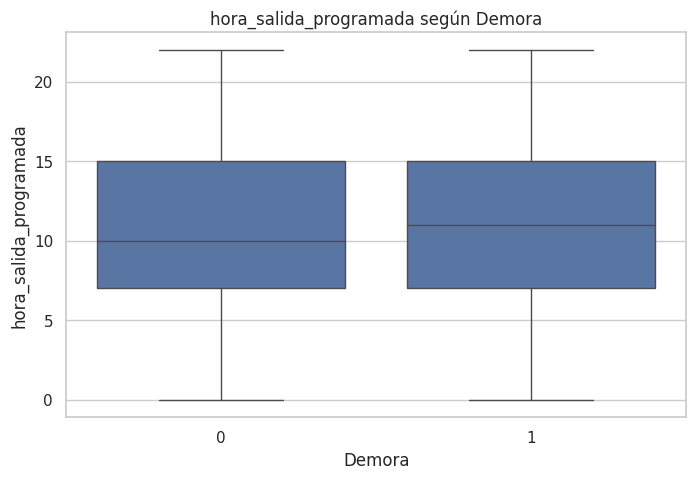

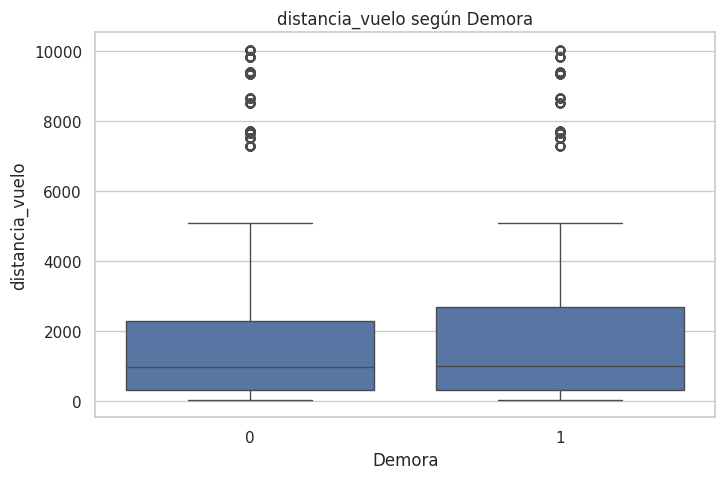

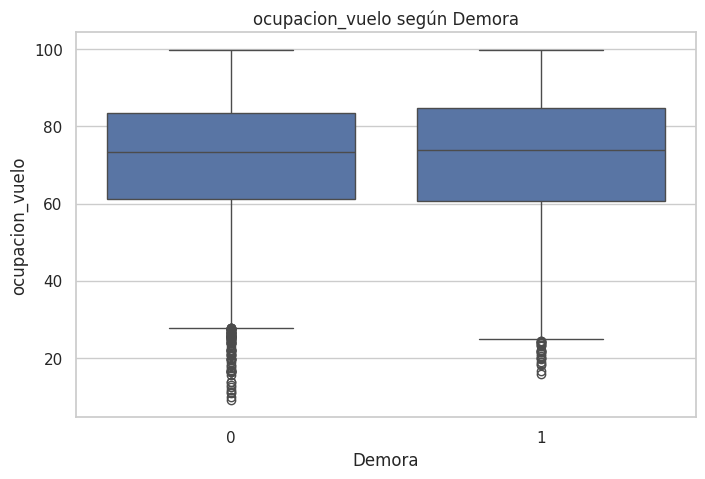

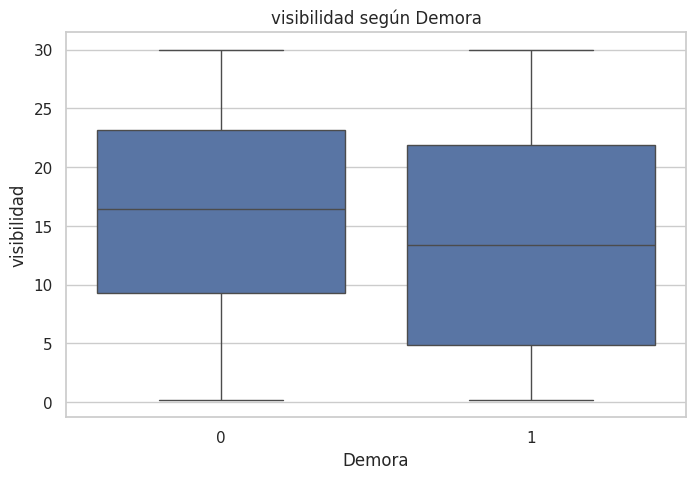

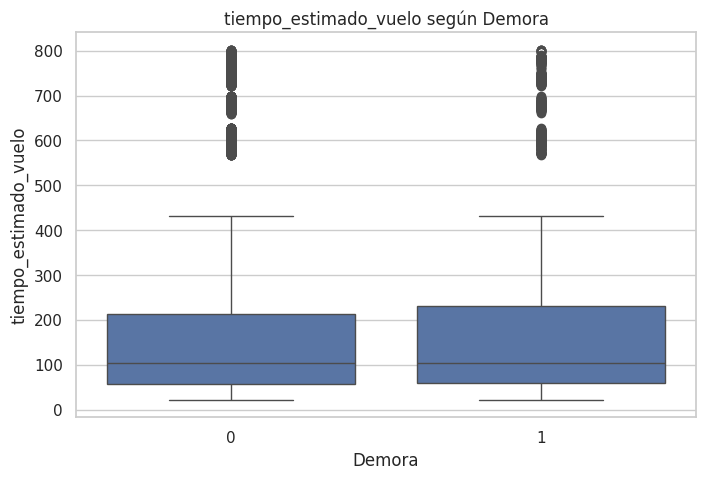

In [ ]:

vars_numericas = [
    'hora_salida_programada',
    'distancia_vuelo',
    'ocupacion_vuelo',
    'visibilidad',
    'tiempo_estimado_vuelo'
]
print("=== ANÁLISIS ESTADÍSTICO NUMÉRICO SEGÚN DEMORA ===")
for var in vars_numericas:
    print(f"\nEstadísticos de '{var}' agrupados por Demora:")
    # Calculamos media, mediana y desvío para ver la diferencia real
    resumen = df_vuelos.groupby('demora')[var].agg(['mean', 'median', 'std']).round(2)
    print(resumen)

    # Cálculo de la diferencia porcentual de las medias
    media_0 = resumen.loc[0, 'mean']
    media_1 = resumen.loc[1, 'mean']
    dif_perc = ((media_1 - media_0) / media_0) * 100
    print(f"Diferencia porcentual en la media: {dif_perc:.2f}%")

for var in vars_numericas:

    plt.figure(figsize=(8,5))

    sns.boxplot(
        data=df_vuelos,
        x='demora',
        y=var
    )

    plt.title(f'{var} según Demora')
    plt.xlabel('Demora')
    plt.ylabel(var)

    plt.show()

#### 2.4.2 Distribuciones según Demora

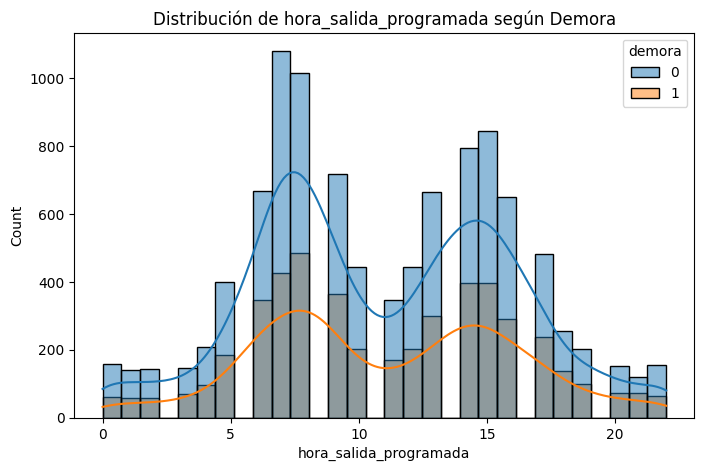

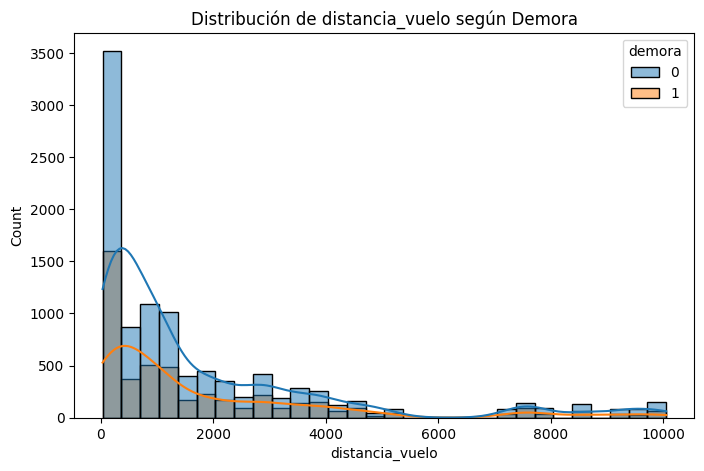

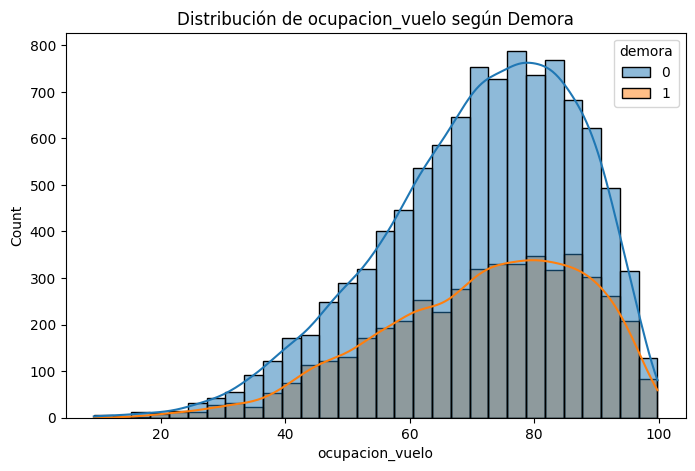

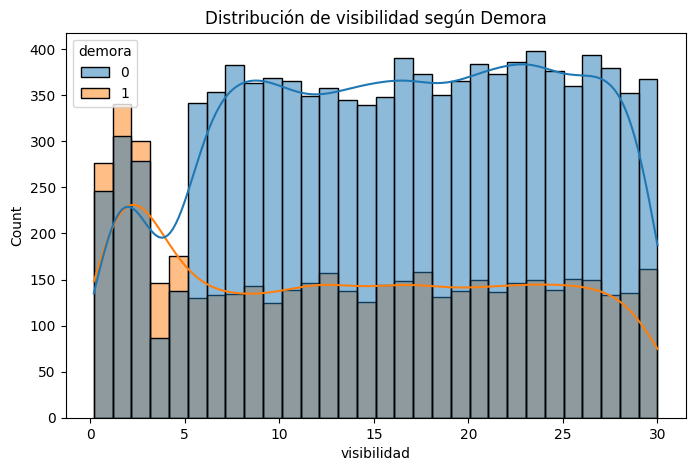

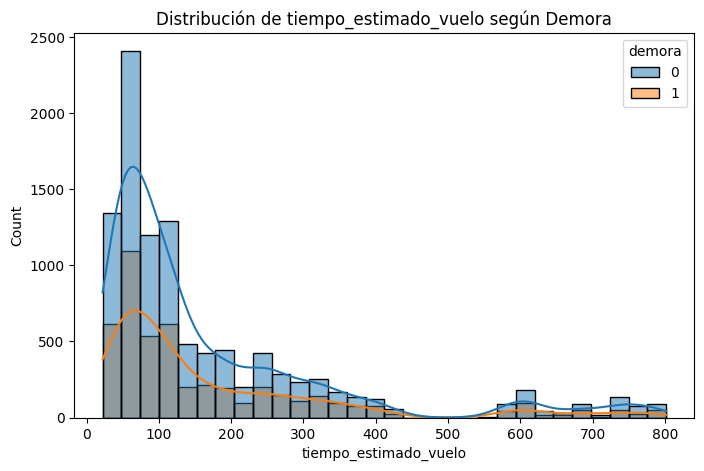

In [ ]:
for var in vars_numericas:

    plt.figure(figsize=(8,5))

    sns.histplot(
        data=df_vuelos,
        x=var,
        hue='demora',
        kde=True,
        bins=30
    )

    plt.title(f'Distribución de {var} según Demora')

    plt.show()

#### 2.4.3 Matriz de Correlación

                        hora_salida_programada  distancia_vuelo  \
hora_salida_programada                1.000000         0.008558   
distancia_vuelo                       0.008558         1.000000   
ocupacion_vuelo                      -0.002905         0.009143   
visibilidad                           0.010043         0.008574   
tiempo_estimado_vuelo                 0.008228         0.998735   
demora                                0.012674         0.008190   

                        ocupacion_vuelo  visibilidad  tiempo_estimado_vuelo  \
hora_salida_programada        -0.002905     0.010043               0.008228   
distancia_vuelo                0.009143     0.008574               0.998735   
ocupacion_vuelo                1.000000     0.013661               0.009361   
visibilidad                    0.013661     1.000000               0.008555   
tiempo_estimado_vuelo          0.009361     0.008555               1.000000   
demora                         0.014905    -0.127020    

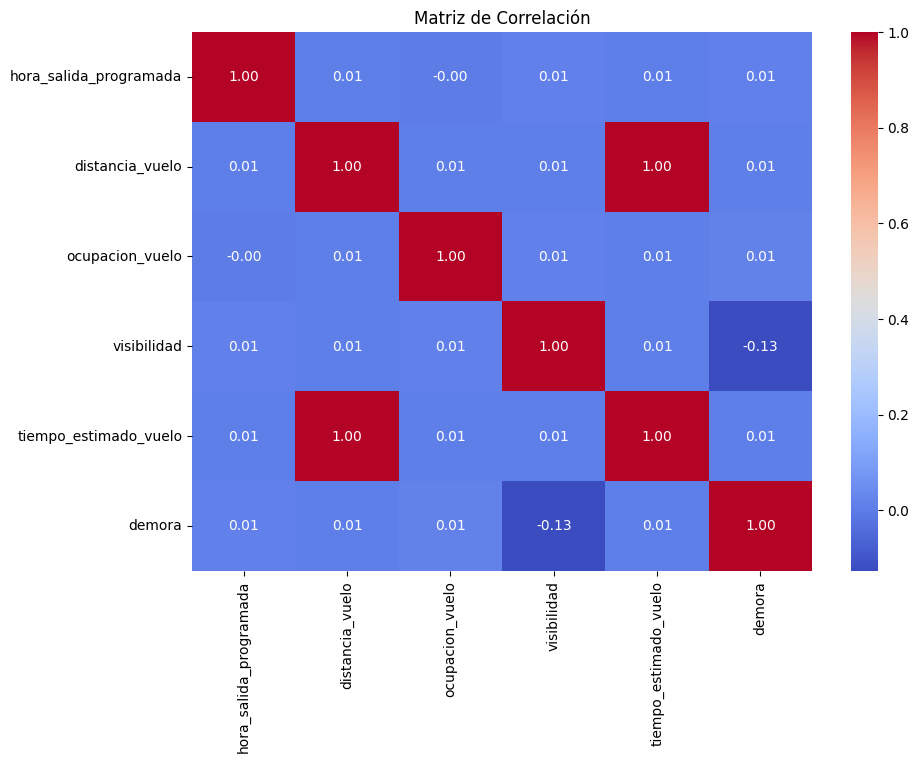

In [ ]:
corr = df_vuelos[[
    'hora_salida_programada',
    'distancia_vuelo',
    'ocupacion_vuelo',
    'visibilidad',
    'tiempo_estimado_vuelo',
    'demora'
]].corr()

print(corr)

plt.figure(figsize=(10,7))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlación')

plt.show()

#### 2.4.4 Matriz de Covarianza

                        hora_salida_programada  distancia_vuelo  \
hora_salida_programada               24.428734     9.629961e+01   
distancia_vuelo                      96.299609     5.183139e+06   
ocupacion_vuelo                      -0.229187     3.323044e+02   
visibilidad                           0.428558     1.685230e+02   
tiempo_estimado_vuelo                 6.954650     3.888387e+05   
demora                                0.029187     8.687993e+00   

                        ocupacion_vuelo  visibilidad  tiempo_estimado_vuelo  \
hora_salida_programada        -0.229187     0.428558               6.954650   
distancia_vuelo              332.304359   168.522998          388838.717868   
ocupacion_vuelo              254.873196     1.882840              25.555537   
visibilidad                    1.882840    74.535666              12.630705   
tiempo_estimado_vuelo         25.555537    12.630705           29244.619549   
demora                         0.110865    -0.510938    

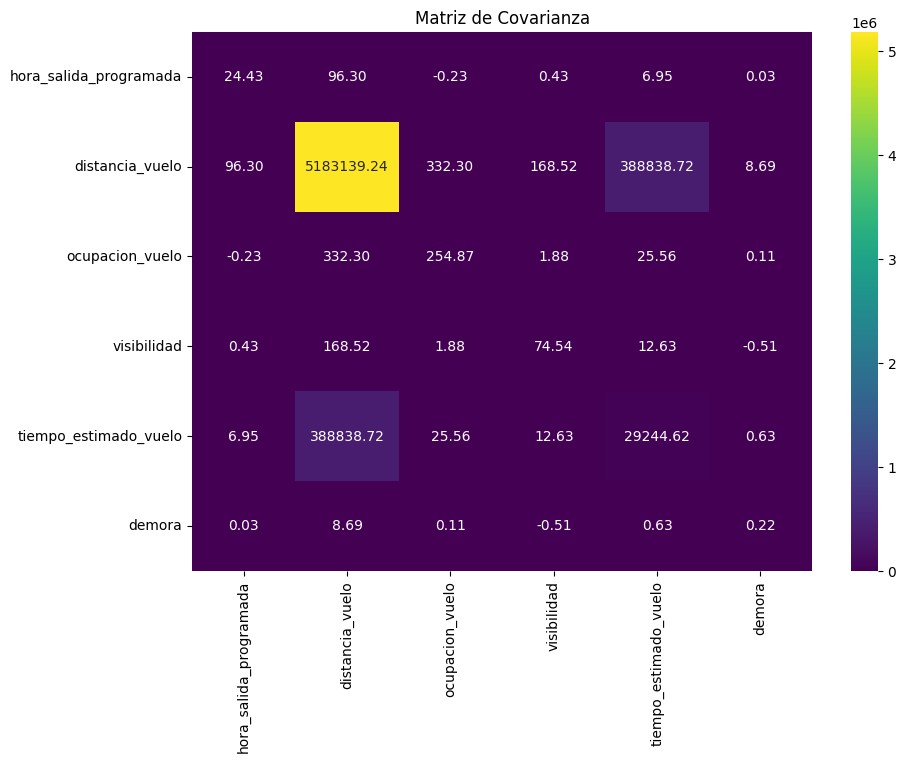

In [ ]:
cov = df_vuelos[[
    'hora_salida_programada',
    'distancia_vuelo',
    'ocupacion_vuelo',
    'visibilidad',
    'tiempo_estimado_vuelo',
    'demora'
]].cov()

print(cov)

plt.figure(figsize=(10,7))

sns.heatmap(
    cov,
    annot=True,
    cmap='viridis',
    fmt='.2f'
)

plt.title('Matriz de Covarianza')

plt.show()

#### 2.4.5 Relación Distancia vs Tiempo Estimado

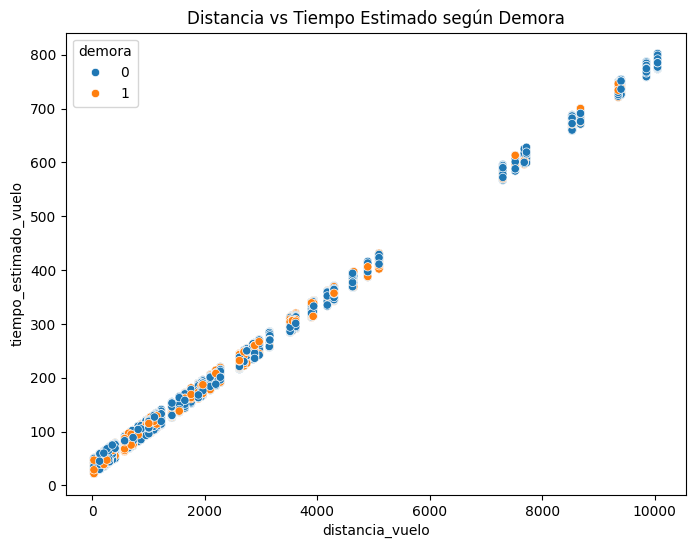

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df_vuelos,
    x='distancia_vuelo',
    y='tiempo_estimado_vuelo',
    hue='demora'
)

plt.title('Distancia vs Tiempo Estimado según Demora')

plt.show()

#### 2.4.6 Relación entre Visibilidad y Condiciones Climáticas

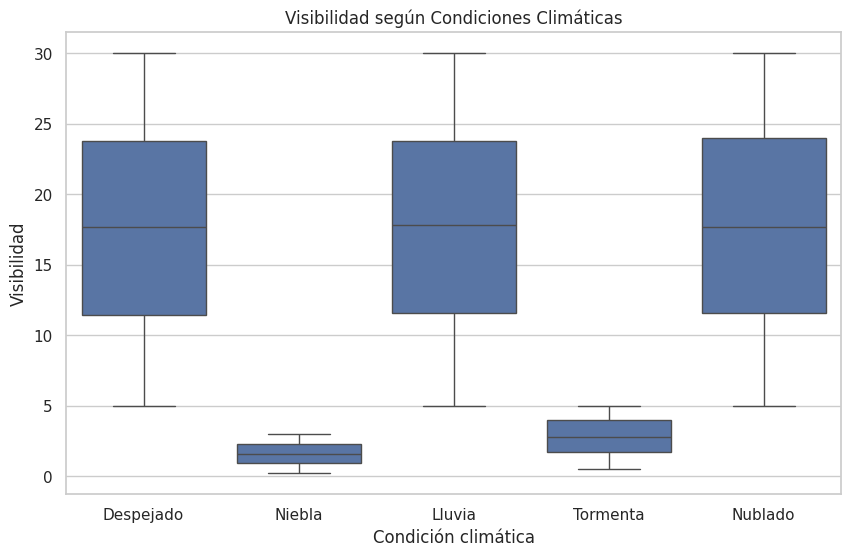

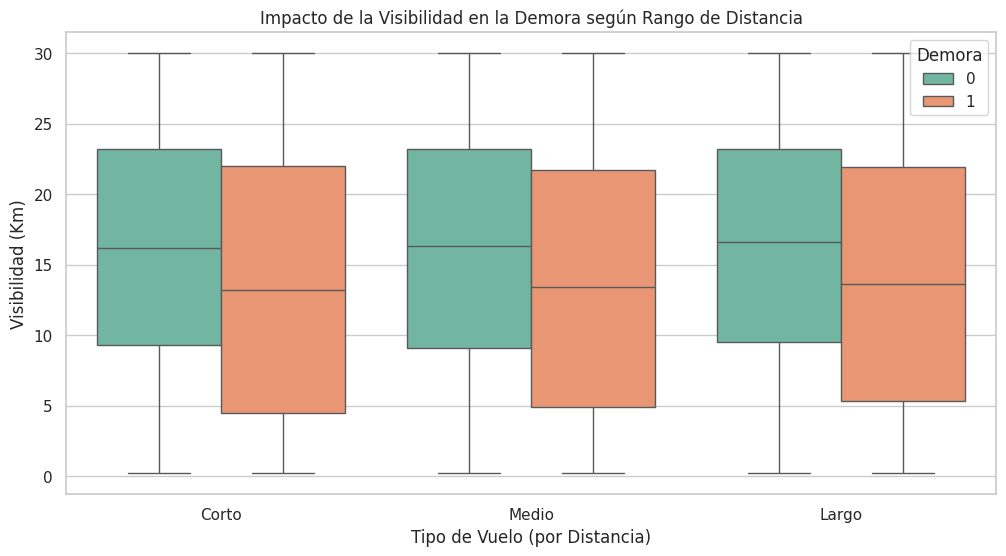

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df_vuelos,
    x='condiciones_climaticas',
    y='visibilidad'
)

plt.title('Visibilidad según Condiciones Climáticas')
plt.xlabel('Condición climática')
plt.ylabel('Visibilidad')

plt.show()
# Creamos categorías de distancia para que el análisis sea legible
df_vuelos['rango_distancia'] = pd.qcut(df_vuelos['distancia_vuelo'], q=3, labels=['Corto', 'Medio', 'Largo'])

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_vuelos, x='rango_distancia', y='visibilidad', hue='demora', palette='Set2')

plt.title('Impacto de la Visibilidad en la Demora según Rango de Distancia')
plt.xlabel('Tipo de Vuelo (por Distancia)')
plt.ylabel('Visibilidad (Km)')
plt.legend(title='Demora', loc='upper right')
plt.show()


#### 2.4.7 Relación entre Congestión Aérea y Tiempo Estimado de Vuelo

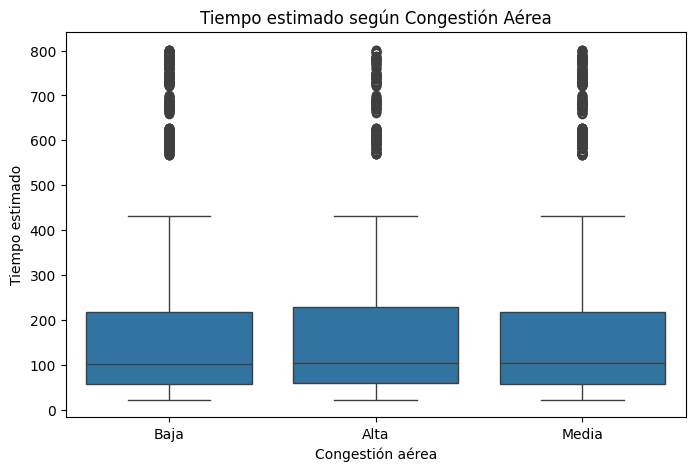

In [ ]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df_vuelos,
    x='congestion_aerea',
    y='tiempo_estimado_vuelo'
)

plt.title('Tiempo estimado según Congestión Aérea')
plt.xlabel('Congestión aérea')
plt.ylabel('Tiempo estimado')

plt.show()

#### hora salida vs congestion aerea

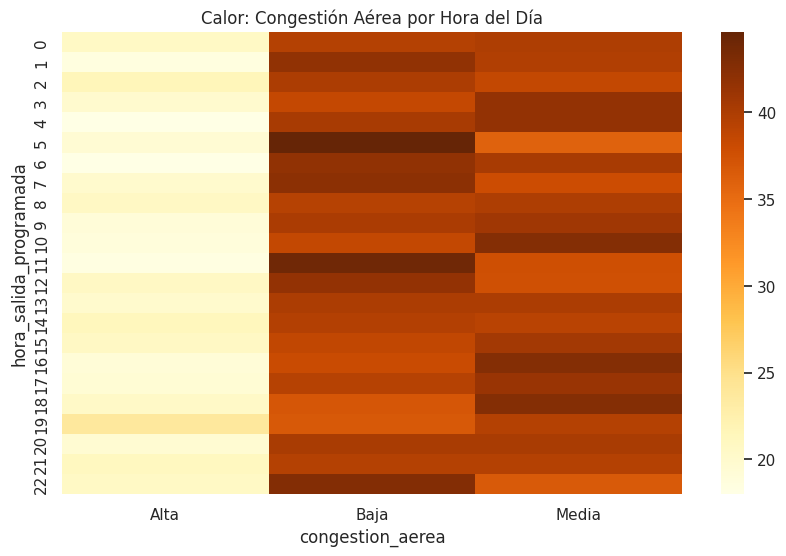

In [ ]:
# Usamos la franja_horaria que creamos antes o la hora_salida_programada
plt.figure(figsize=(10,6))
tabla_hora_cong = pd.crosstab(df_vuelos['hora_salida_programada'], df_vuelos['congestion_aerea'], normalize='index') * 100
sns.heatmap(tabla_hora_cong, annot=False, cmap="YlOrBr")
plt.title('Calor: Congestión Aérea por Hora del Día')
plt.show()


#### 2.4.8 Relación entre Temporada Alta y Demora

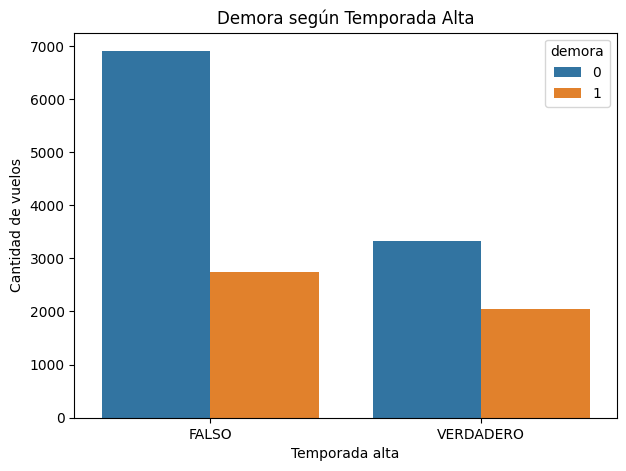

/tmp/ipykernel_3398/1585410587.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


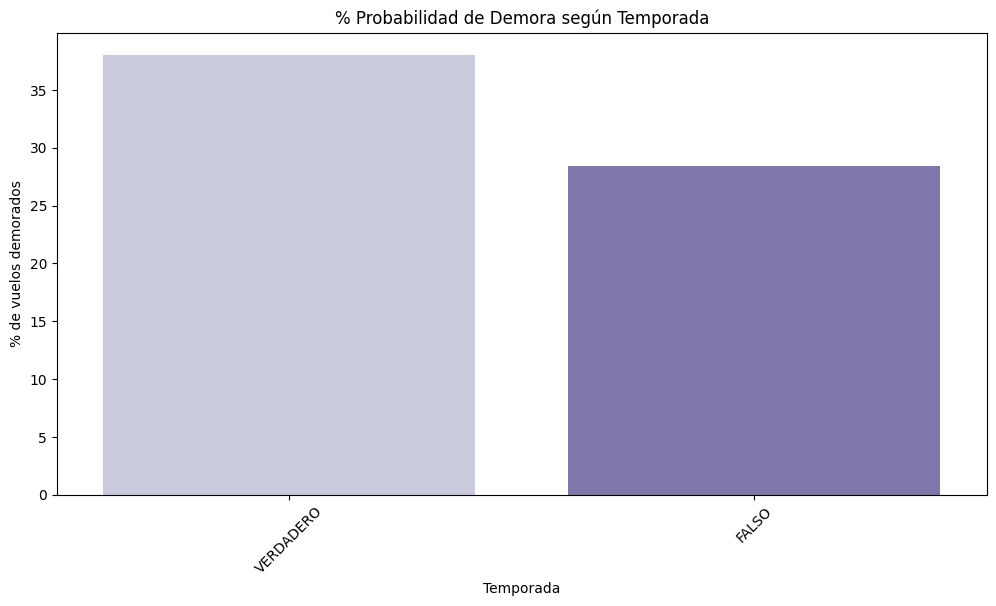

temporada_alta
VERDADERO    38.043681
FALSO        28.414394
Name: demora, dtype: float64


In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    data=df_vuelos,
    x='temporada_alta',
    hue='demora'
)

plt.title('Demora según Temporada Alta')
plt.xlabel('Temporada alta')
plt.ylabel('Cantidad de vuelos')

plt.show()
prob_temp = (
    df_vuelos.groupby('temporada_alta')['demora']
    .mean()
    .sort_values(ascending=False) * 100
)
plt.figure(figsize=(12,6))

sns.barplot(
    x=prob_temp.index,
    y=prob_temp.values,
    palette='Purples'
)

plt.title('% Probabilidad de Demora según Temporada')
plt.xlabel('Temporada')
plt.ylabel('% de vuelos demorados')

plt.xticks(rotation=45)
plt.show()

print(prob_temp)

#### 2.4.9 Relación entre Día de la Semana y Demora

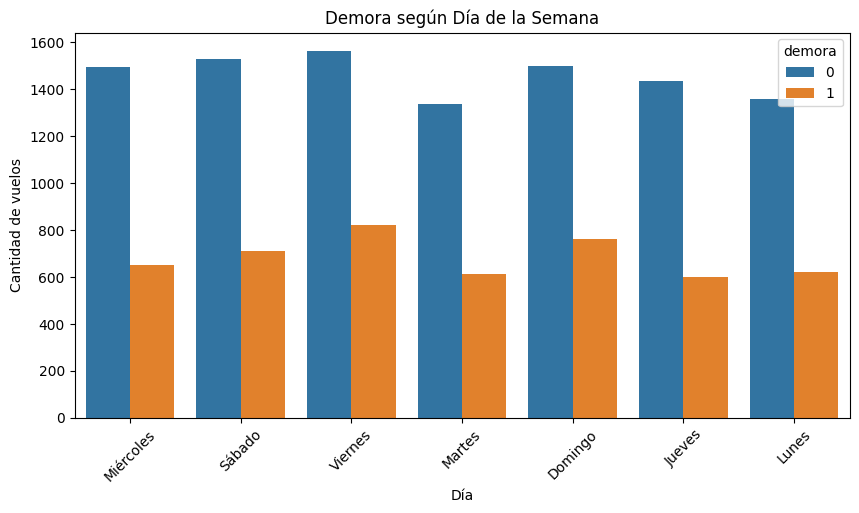

/tmp/ipykernel_3398/3494466687.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


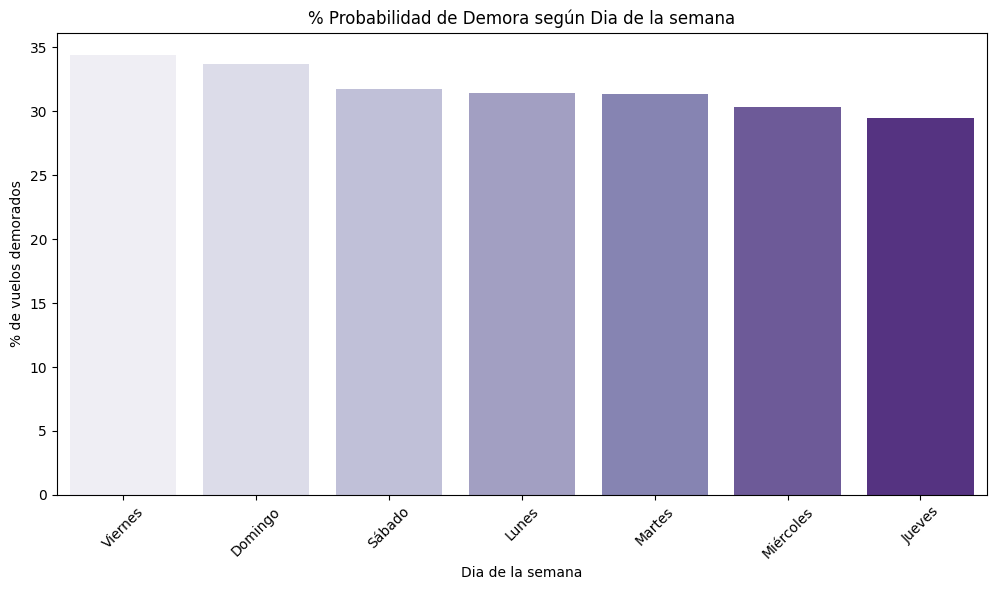

dia_semana
Viernes      34.423480
Domingo      33.716306
Sábado       31.743201
Lunes        31.395349
Martes       31.346351
Miércoles    30.339693
Jueves       29.420432
Name: demora, dtype: float64


In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(
    data=df_vuelos,
    x='dia_semana',
    hue='demora'
)

plt.title('Demora según Día de la Semana')
plt.xlabel('Día')
plt.ylabel('Cantidad de vuelos')

plt.xticks(rotation=45)

plt.show()
prob_dia = (
    df_vuelos.groupby('dia_semana')['demora']
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=prob_dia.index,
    y=prob_dia.values,
    palette='Purples'
)

plt.title('% Probabilidad de Demora según Dia de la semana')
plt.xlabel('Dia de la semana')
plt.ylabel('% de vuelos demorados')

plt.xticks(rotation=45)
plt.show()

print(prob_dia)

#### 2.4.10 Relación entre Tipo de Avión y Demora

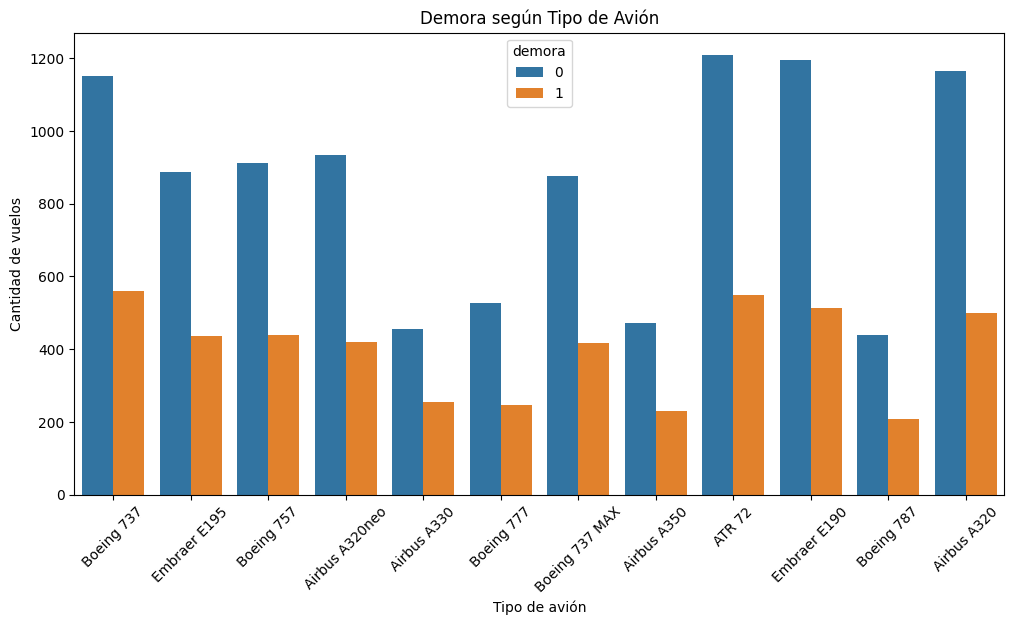

/tmp/ipykernel_3398/1703014606.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


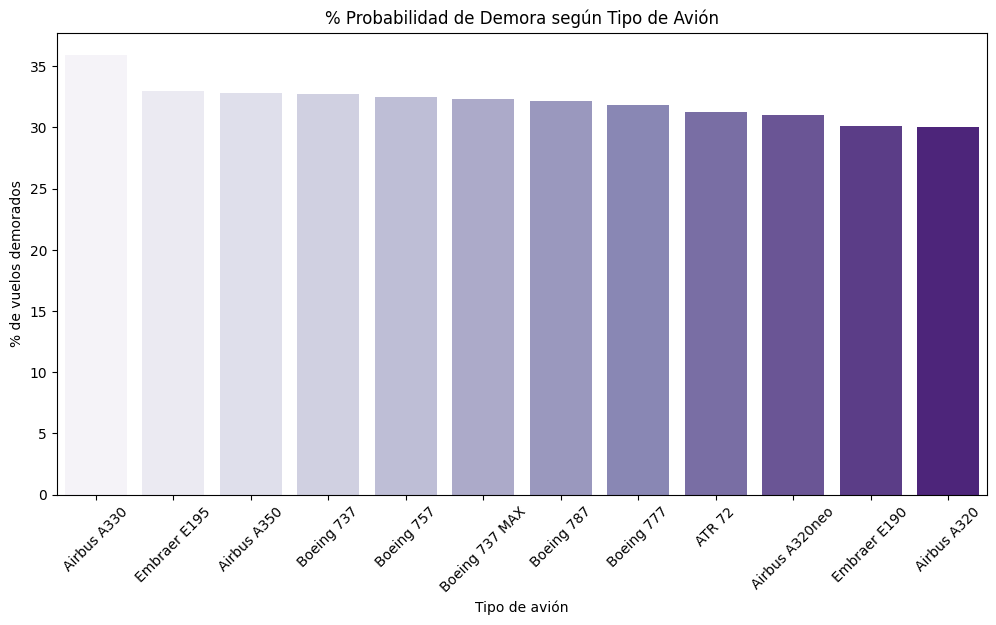

tipo_avion
Airbus A330       35.955056
Embraer E195      32.955404
Airbus A350       32.812500
Boeing 737        32.748538
Boeing 757        32.470414
Boeing 737 MAX    32.302937
Boeing 787        32.198142
Boeing 777        31.870968
ATR 72            31.250000
Airbus A320neo    30.991124
Embraer E190      30.093677
Airbus A320       30.048077
Name: demora, dtype: float64


In [ ]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df_vuelos,
    x='tipo_avion',
    hue='demora'
)

plt.title('Demora según Tipo de Avión')
plt.xlabel('Tipo de avión')
plt.ylabel('Cantidad de vuelos')

plt.xticks(rotation=45)

plt.show()
prob_avion = (
    df_vuelos.groupby('tipo_avion')['demora']
    .mean()
    .sort_values(ascending=False) * 100
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=prob_avion.index,
    y=prob_avion.values,
    palette='Purples'
)

plt.title('% Probabilidad de Demora según Tipo de Avión')
plt.xlabel('Tipo de avión')
plt.ylabel('% de vuelos demorados')

plt.xticks(rotation=45)
plt.show()

print(prob_avion)

#### Probabilidad de demora cruzando Clima y Congestión

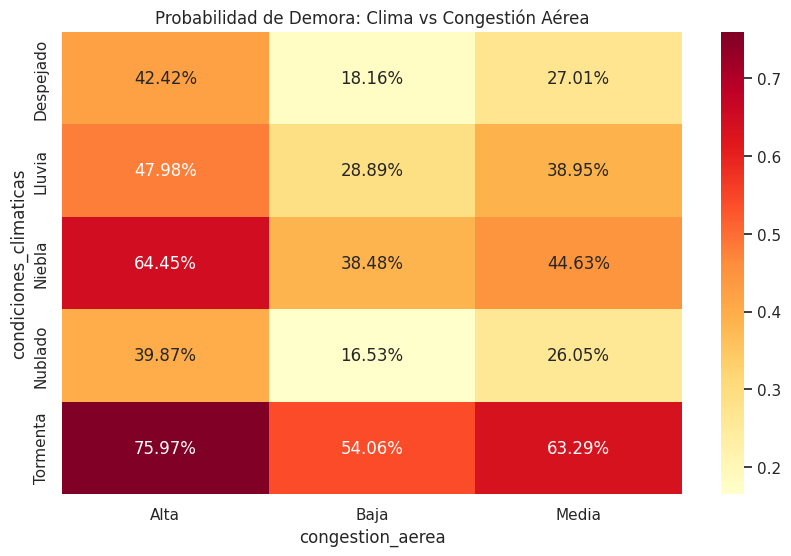

In [ ]:
pivot_table = df_vuelos.pivot_table(index='condiciones_climaticas',
                                    columns='congestion_aerea',
                                    values='demora',
                                    aggfunc='mean')

plt.figure(figsize=(10,6))
sns.heatmap(pivot_table, annot=True, cmap='YlOrRd', fmt='.2%')
plt.title('Probabilidad de Demora: Clima vs Congestión Aérea')
plt.show()

# Sección nueva

In [ ]:
print("=== ESTADÍSTICOS DE INTERACCIÓN ENTRE VARIABLES ===")

# 1. Visibilidad promedio por Condición Climática (Para el Boxplot de Visibilidad vs Clima)
print("\n1. Tabla: Visibilidad por Condición Climática:")
stats_clima_vis = df_vuelos.groupby('condiciones_climaticas')['visibilidad'].agg(['mean', 'std', 'median']).round(2)
print(stats_clima_vis)

# 2. Visibilidad promedio por Rango de Distancia y Demora (Para el Boxplot de 3 variables)
print("\n2. Tabla: Visibilidad por Rango de Distancia y Estado de Demora:")
stats_dist_vis_dem = df_vuelos.groupby(['rango_distancia', 'demora'])['visibilidad'].mean().unstack().round(2)
print(stats_dist_vis_dem)

# 3. Tiempo Estimado por Congestión (Para el Boxplot de Congestión vs Tiempo)
print("\n3. Tabla: Tiempo Estimado por Nivel de Congestión:")
stats_cong_tiempo = df_vuelos.groupby('congestion_aerea')['tiempo_estimado_vuelo'].agg(['mean', 'std']).round(2)
print(stats_cong_tiempo)

=== ESTADÍSTICOS DE INTERACCIÓN ENTRE VARIABLES ===

1. Tabla: Visibilidad por Condición Climática:
                         mean   std  median
condiciones_climaticas                     
Despejado               17.65  7.20    17.7
Lluvia                  17.68  7.21    17.8
Niebla                   1.60  0.81     1.6
Nublado                 17.72  7.17    17.7
Tormenta                 2.79  1.31     2.8

2. Tabla: Visibilidad por Rango de Distancia y Estado de Demora:
demora               0      1
rango_distancia              
Corto            16.04  13.68
Medio            16.04  13.67
Largo            16.29  13.94

3. Tabla: Tiempo Estimado por Nivel de Congestión:
                    mean     std
congestion_aerea                
Alta              171.44  170.52
Baja              170.29  173.44
Media             168.67  168.79


/tmp/ipykernel_3398/309885034.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats_dist_vis_dem = df_vuelos.groupby(['rango_distancia', 'demora'])['visibilidad'].mean().unstack().round(2)


# Sección nueva

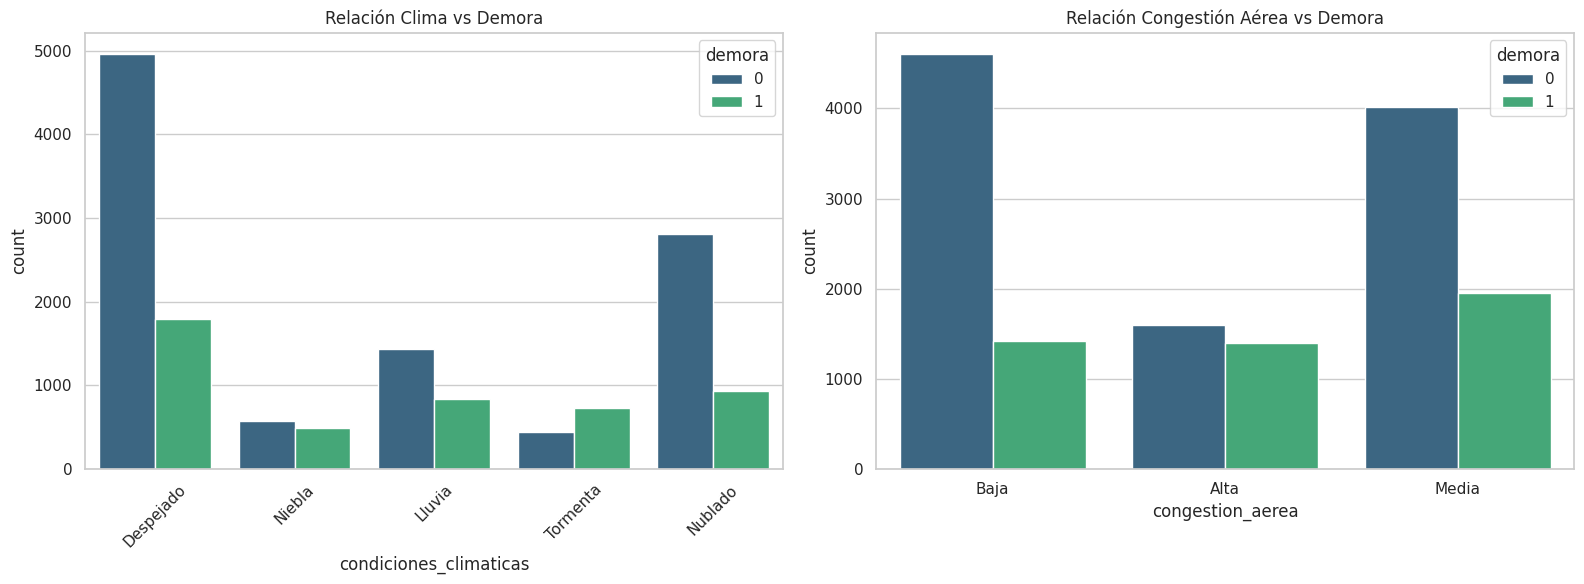

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(ax=axes[0], data=df_vuelos, x='condiciones_climaticas', hue='demora', palette='viridis')
axes[0].set_title('Relación Clima vs Demora')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(ax=axes[1], data=df_vuelos, x='congestion_aerea', hue='demora', palette='viridis')
axes[1].set_title('Relación Congestión Aérea vs Demora')

plt.tight_layout()
plt.show()

/tmp/ipykernel_11627/2761476234.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x=prob_clima.index, y=prob_clima.values, palette='Reds_r')
/tmp/ipykernel_11627/2761476234.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], x=prob_congestion.index, y=prob_congestion.values, palette='Blues_r')


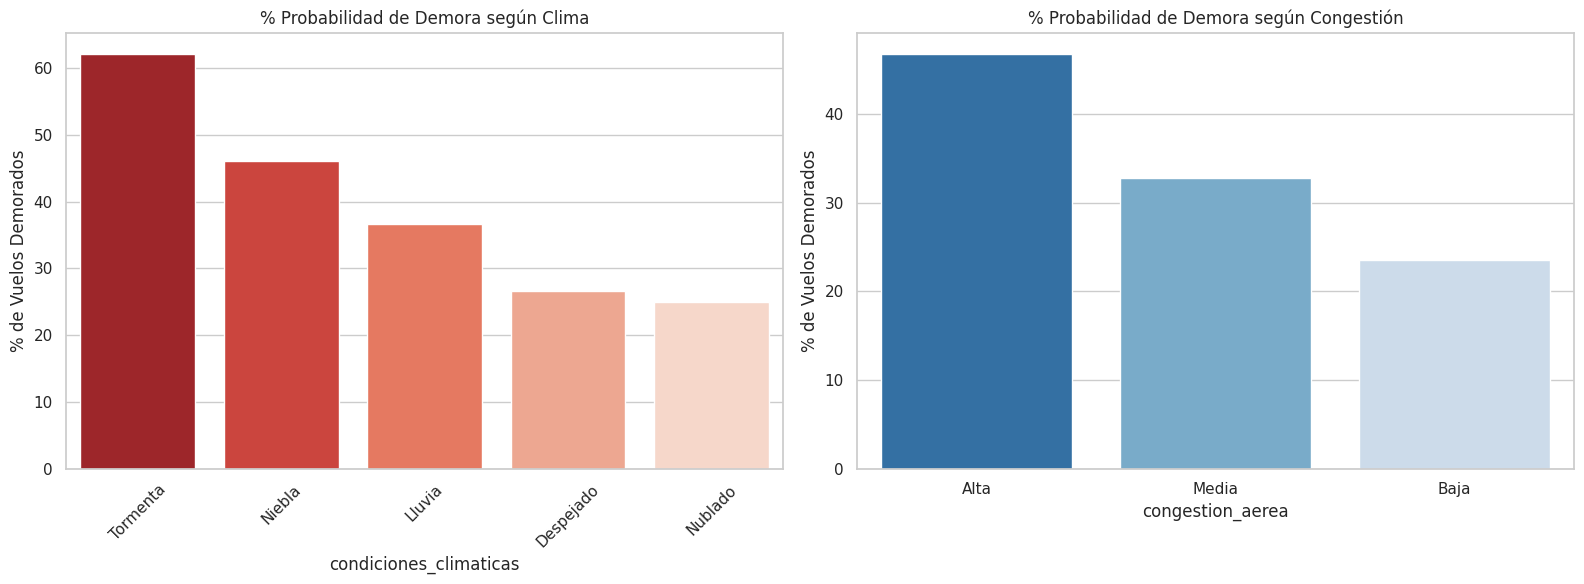

Probabilidad de demora por Clima:
condiciones_climaticas
Tormenta     62.127660
Niebla       46.132075
Lluvia       36.700485
Despejado    26.549327
Nublado      24.939791
Name: demora, dtype: float64

Probabilidad de demora por Congestión:
congestion_aerea
Alta     46.775810
Media    32.736701
Baja     23.569414
Name: demora, dtype: float64


In [ ]:
prob_clima = df_vuelos.groupby('condiciones_climaticas')['demora'].mean().sort_values(ascending=False) * 100

prob_congestion = df_vuelos.groupby('congestion_aerea')['demora'].mean().sort_values(ascending=False) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(ax=axes[0], x=prob_clima.index, y=prob_clima.values, palette='Reds_r')
axes[0].set_title('% Probabilidad de Demora según Clima')
axes[0].set_ylabel('% de Vuelos Demorados')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(ax=axes[1], x=prob_congestion.index, y=prob_congestion.values, palette='Blues_r')
axes[1].set_title('% Probabilidad de Demora según Congestión')
axes[1].set_ylabel('% de Vuelos Demorados')

plt.tight_layout()
plt.show()

print("Probabilidad de demora por Clima:")
print(prob_clima)

print("\nProbabilidad de demora por Congestión:")
print(prob_congestion)

### 2.4. Análisis de Variables Numéricas y Outliers

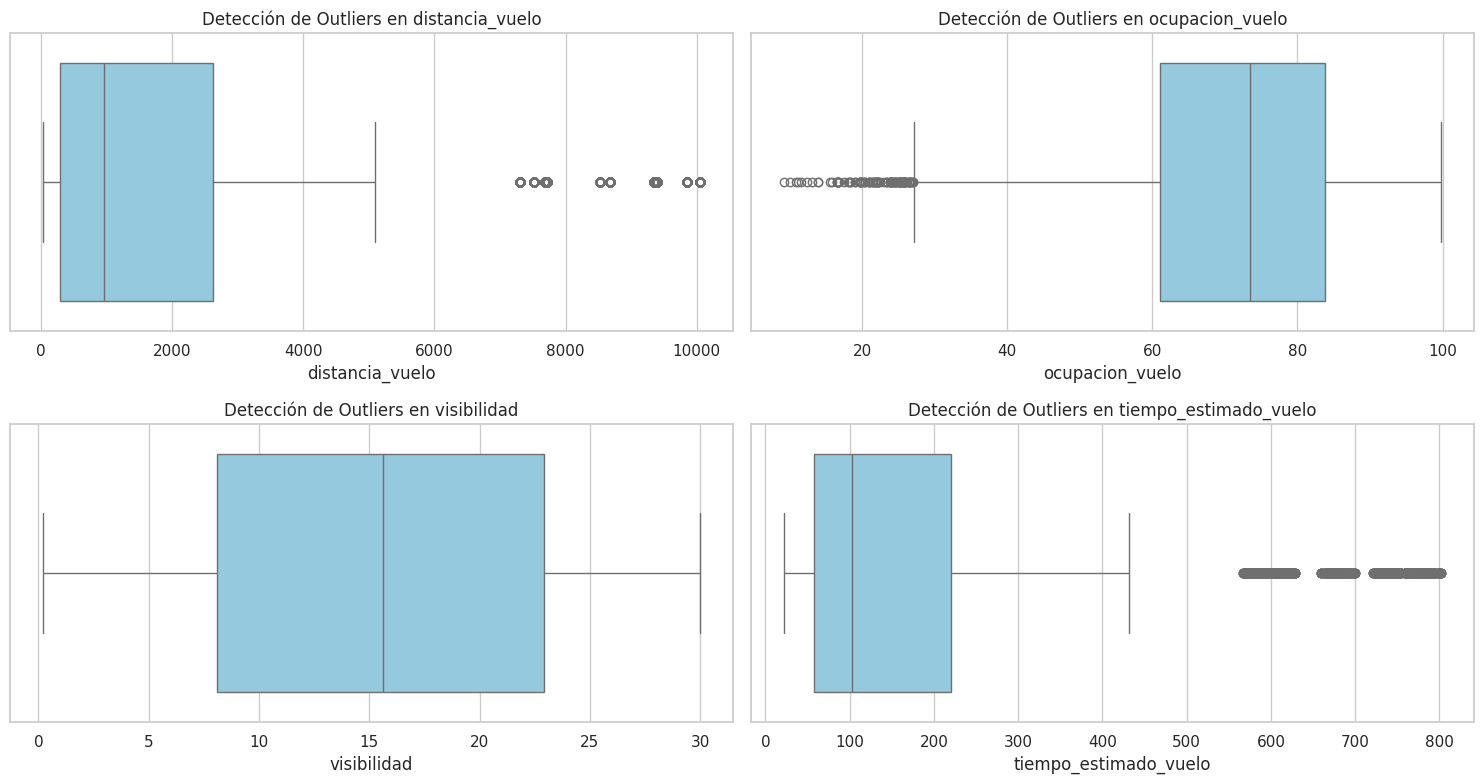


--- Resumen Estadístico de Variables Numéricas ---


,distancia_vuelo,ocupacion_vuelo,visibilidad,tiempo_estimado_vuelo
count,15000.000000,15000.000000,15000.000000,15000.000000
mean,1811.709667,71.383327,15.371927,169.874467
std,2276.650883,15.964749,8.633404,171.010583
min,35.000000,9.200000,0.200000,22.000000
25%,300.000000,61.100000,8.100000,58.000000
50%,960.000000,73.400000,15.600000,103.000000
75%,2620.000000,83.800000,22.900000,220.000000
max,10050.000000,99.800000,30.000000,802.000000



--- DETECCIÓN PROGRAMÁTICA DE OUTLIERS (Método IQR) ---
distancia_vuelo: 1098 outliers detectados (7.32%)
ocupacion_vuelo: 105 outliers detectados (0.70%)
visibilidad: 0 outliers detectados (0.00%)
tiempo_estimado_vuelo: 1098 outliers detectados (7.32%)

Correlación entre Distancia y Tiempo Estimado: 0.9987

--- Impacto de Vuelos Largos (Outliers) en la Demora ---
es_outlier_distancia
False    31.894691
True     31.329690
Name: demora, dtype: float64


In [ ]:
vars_numericas = ['distancia_vuelo', 'ocupacion_vuelo', 'visibilidad', 'tiempo_estimado_vuelo']

plt.figure(figsize=(15, 8))
for i, var in enumerate(vars_numericas):
    plt.subplot(2, 2, i+1)
    sns.boxplot(x=df_vuelos[var], color='skyblue')
    plt.title(f'Detección de Outliers en {var}')

plt.tight_layout()
plt.show()

print("\n--- Resumen Estadístico de Variables Numéricas ---")
display(df_vuelos[vars_numericas].describe())
print("\n--- DETECCIÓN PROGRAMÁTICA DE OUTLIERS (Método IQR) ---")
for var in vars_numericas:
    Q1 = df_vuelos[var].quantile(0.25)
    Q3 = df_vuelos[var].quantile(0.75)
    IQR = Q3 - Q1
    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    outliers = df_vuelos[(df_vuelos[var] < limite_inf) | (df_vuelos[var] > limite_sup)]
    print(f"{var}: {len(outliers)} outliers detectados ({len(outliers)/len(df_vuelos)*100:.2f}%)")
    # Verificamos la correlación entre las dos variables con outliers coincidentes
corr_dist_tiempo = df_vuelos['distancia_vuelo'].corr(df_vuelos['tiempo_estimado_vuelo'])
print(f"\nCorrelación entre Distancia y Tiempo Estimado: {corr_dist_tiempo:.4f}")
# Analizamos si los outliers de distancia tienen más demoras
Q3 = df_vuelos['distancia_vuelo'].quantile(0.75)
IQR = df_vuelos['distancia_vuelo'].quantile(0.75) - df_vuelos['distancia_vuelo'].quantile(0.25)
limite_sup = Q3 + 1.5 * IQR

df_vuelos['es_outlier_distancia'] = df_vuelos['distancia_vuelo'] > limite_sup

print("\n--- Impacto de Vuelos Largos (Outliers) en la Demora ---")
print(df_vuelos.groupby('es_outlier_distancia')['demora'].mean() * 100)

## Fase 3: Preparación de los Datos

### 3.1. Selección de Variables y Limpieza

In [ ]:
cols_a_eliminar = ['id_vuelo', 'puerta_embarque']
df_vuelos_prep = df_vuelos.drop(columns=cols_a_eliminar)

df_vuelos_prep = df_vuelos_prep.dropna()

### 3.2. Transformación de Variables Categóricas (Encoding)

In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

cols_categoricas = ['aeropuerto_origen', 'aeropuerto_destino', 'dia_semana',
                   'condiciones_climaticas', 'congestion_aerea', 'tipo_avion']

for col in cols_categoricas:
    df_vuelos_prep[col] = le.fit_transform(df_vuelos_prep[col])

if 'temporada_alta' in df_vuelos_prep.columns and df_vuelos_prep['temporada_alta'].dtype == 'object':
    df_vuelos_prep['temporada_alta'] = df_vuelos_prep['temporada_alta'].map({'VERDADERO': 1, 'FALSO': 0})

print("Datos transformados (primeras filas):")
display(df_vuelos_prep.head())

Datos transformados (primeras filas):


,aeropuerto_origen,aeropuerto_destino,hora_salida_programada,dia_semana,distancia_vuelo,condiciones_climaticas,congestion_aerea,tipo_avion,ocupacion_vuelo,temporada_alta,visibilidad,tiempo_estimado_vuelo,demora
0,17,18,09:30,4,360,0,1,5,52.8,False,12.2,57,1
1,38,15,11:00,5,1230,0,0,11,54.4,True,10.7,132,1
2,27,33,08:15,6,2280,2,2,7,48.7,True,1.0,199,0
3,32,18,06:45,3,1110,0,1,2,68.0,False,15.8,109,1
4,33,15,11:30,0,5100,0,1,3,92.0,True,23.0,421,0


### 3.3. División de Datos y Escalado

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#if df_vuelos_prep['hora_salida_programada'].dtype == 'object':
#    df_vuelos_prep['hora_salida_programada'] = df_vuelos_prep['hora_salida_programada'].str.split(':').str[0].astype(int)

#for col in ['ocupacion_vuelo', 'visibilidad']:
#    if df_vuelos_prep[col].dtype == 'object':
#        df_vuelos_prep[col] = df_vuelos_prep[col].str.replace(',', '.', regex=False).astype(float)

X = df_vuelos_prep.drop('demora', axis=1)
y = df_vuelos_prep['demora']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Muestras de entrenamiento: {X_train.shape[0]}")
print(f"Muestras de testeo: {X_test.shape[0]}")

Muestras de entrenamiento: 10500
Muestras de testeo: 4500


## Fase 4: Modelado - Árbol de Decisión

### 4.1. Entrenamiento del Árbol de Decisión

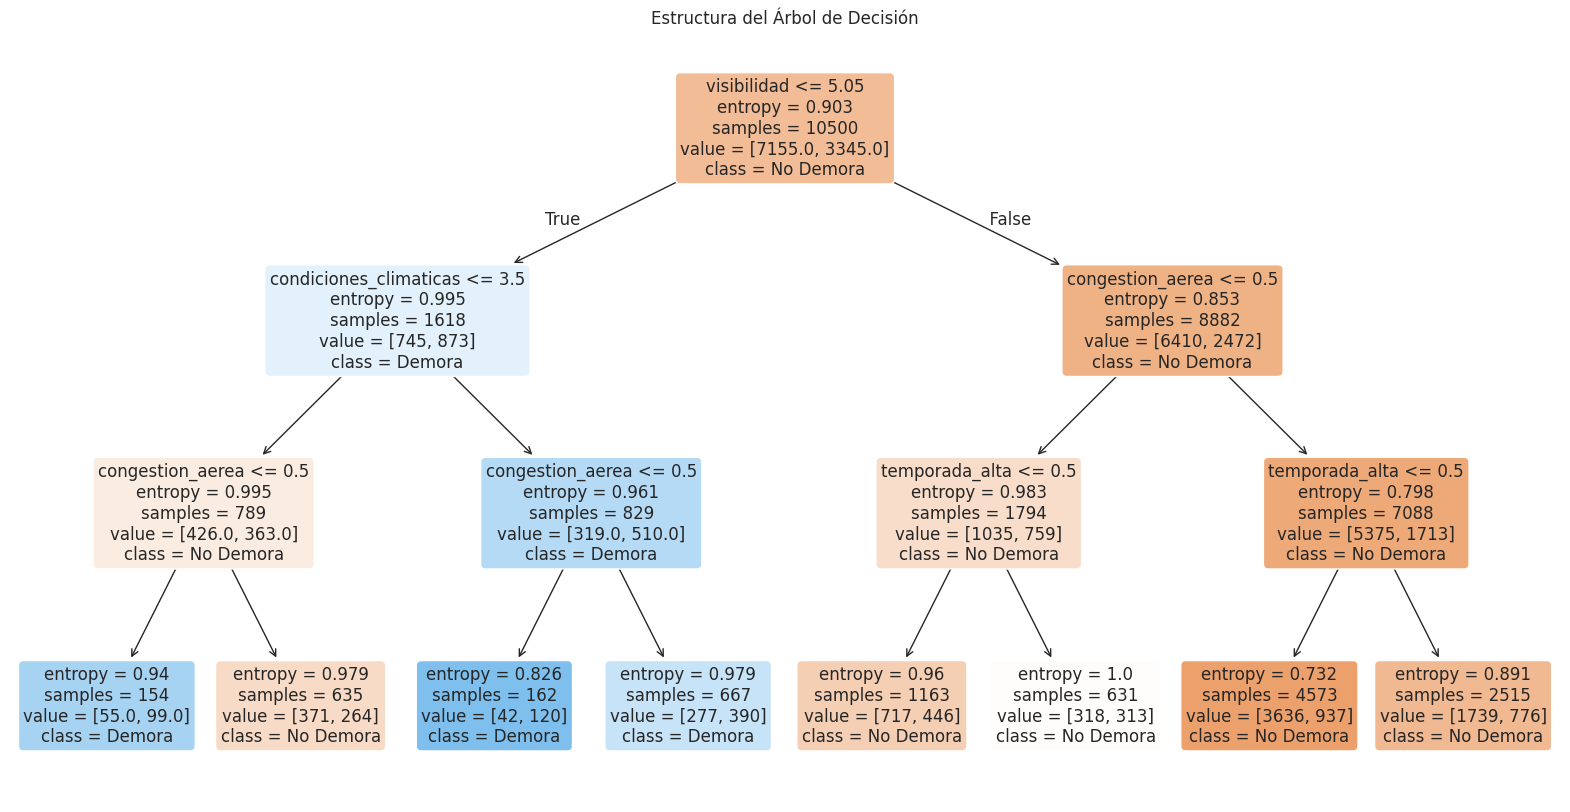

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

modelo_arbol = DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=42)

modelo_arbol.fit(X_train, y_train)

plt.figure(figsize=(20,10))
plot_tree(modelo_arbol,
          feature_names=X.columns,
          class_names=['No Demora', 'Demora'],
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Estructura del Árbol de Decisión")
plt.show()

### 4.2. Entrenamiento de KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

modelo_knn = KNeighborsClassifier(n_neighbors=5)

modelo_knn.fit(X_train_scaled, y_train)

print("Modelos entrenados exitosamente.")

Modelos entrenados exitosamente.


## Fase 5: Evaluación de los Modelos

### 5.1. Comparación de Métricas


--- Evaluación: Árbol de Decisión ---
              precision    recall  f1-score   support

           0       0.71      0.95      0.82      3067
           1       0.64      0.18      0.28      1433

    accuracy                           0.71      4500
   macro avg       0.68      0.57      0.55      4500
weighted avg       0.69      0.71      0.65      4500



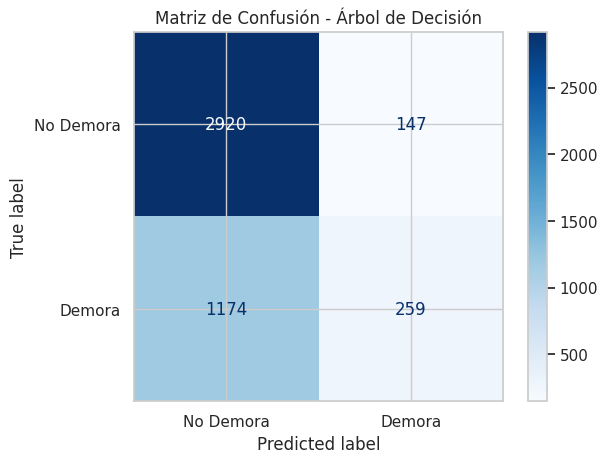


--- Evaluación: KNN ---
              precision    recall  f1-score   support

           0       0.71      0.84      0.77      3067
           1       0.44      0.27      0.33      1433

    accuracy                           0.66      4500
   macro avg       0.57      0.55      0.55      4500
weighted avg       0.62      0.66      0.63      4500



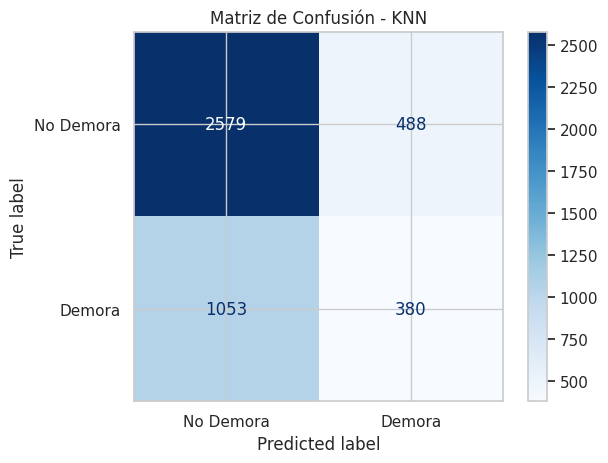

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

def evaluar_modelo(modelo, X_test_data, y_test_true, nombre):
    predicciones = modelo.predict(X_test_data)
    print(f"\n--- Evaluación: {nombre} ---")
    print(classification_report(y_test_true, predicciones))

    cm = confusion_matrix(y_test_true, predicciones)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Demora', 'Demora'])
    disp.plot(cmap='Blues')
    plt.title(f'Matriz de Confusión - {nombre}')
    plt.show()

evaluar_modelo(modelo_arbol, X_test, y_test, "Árbol de Decisión")
evaluar_modelo(modelo_knn, X_test_scaled, y_test, "KNN")

## Fase 6: Implementación

In [ ]:
import pandas as pd

df_vuelos_nuevos_original = df_vuelos_nuevos.copy()

df_vuelos_nuevos = df_vuelos_nuevos.dropna()

# Conversiones
if df_vuelos_nuevos['hora_salida_programada'].dtype == 'object':
    df_vuelos_nuevos['hora_salida_programada'] = (
        df_vuelos_nuevos['hora_salida_programada']
        .str.split(':')
        .str[0]
        .astype(int)
    )

for col in ['ocupacion_vuelo', 'visibilidad']:
    if col in df_vuelos_nuevos.columns and df_vuelos_nuevos[col].dtype == 'object':
        df_vuelos_nuevos[col] = (
            df_vuelos_nuevos[col]
            .str.replace(',', '.', regex=False)
            .astype(float)
        )

if 'temporada_alta' in df_vuelos_nuevos.columns and df_vuelos_nuevos['temporada_alta'].dtype == 'object':
    df_vuelos_nuevos['temporada_alta'] = df_vuelos_nuevos['temporada_alta'].map({
        'VERDADERO': 1,
        'FALSO': 0
    })

# Aplicar Label Encoding a las mismas columnas categóricas
for col in cols_categoricas:
    if col in df_vuelos_nuevos.columns:
        df_vuelos_nuevos[col] = le.fit_transform(df_vuelos_nuevos[col])

# Eliminamos las columnas que no necesitamos
X_nuevos = df_vuelos_nuevos.drop(columns=['id_vuelo', 'puerta_embarque', 'tiempo_estimado_vuelo'])
X_nuevos = X_nuevos[X.columns]

predicciones = modelo_arbol.predict(X_nuevos)

# Agregar predicción al dataframe original
df_vuelos_nuevos_original = df_vuelos_nuevos_original.loc[df_vuelos_nuevos.index].copy()
df_vuelos_nuevos_original['Predicho_demora_vuelo'] = predicciones
df_vuelos_nuevos_original['Predicho_demora_vuelo'] = (
    df_vuelos_nuevos_original['Predicho_demora_vuelo']
    .map({1: 'SI', 0: 'NO'})
)


df_final = df_relacion.merge(
    df_vuelos_nuevos_original,
    on='id_vuelo',
    how='inner'
)


if 'id_pasajero' in df_final.columns and 'id_cliente' not in df_final.columns:
    df_final = df_final.rename(columns={'id_pasajero': 'id_cliente'})

df_final = df_final.merge(
    df_clientes[['id_cliente', 'programaMillas']],
    on='id_cliente',
    how='left'
)


def asignar_beneficio(row):
    if row['Predicho_demora_vuelo'] == 'SI':
        if str(row['programaMillas']).strip().upper() == 'SI':
            return 'Sala VIP'
        else:
            return 'Voucher comida'
    else:
        return 'Ninguno'

df_final['Tipo beneficio'] = df_final.apply(asignar_beneficio, axis=1)


columnas_resultado = [
    'id_vuelo',
    'id_cliente',
    'aeropuerto_origen',
    'aeropuerto_destino',
    'hora_salida_programada',
    'dia_semana',
    'distancia_vuelo',
    'condiciones_climaticas',
    'congestion_aerea',
    'tipo_avion',
    'ocupacion_vuelo',
    'temporada_alta',
    'puerta_embarque',
    'visibilidad',
    'tiempo_estimado_vuelo',
    'Predicho_demora_vuelo',
    'Tipo beneficio'
]

columnas_resultado = [
    col for col in columnas_resultado
    if col in df_final.columns
]

resultado_entregable = df_final[columnas_resultado]


archivo_salida = ruta + "Resultado_Final_Grupo01.xlsx"

resultado_entregable.to_excel(
    archivo_salida,
    index=False
)

print(f"Archivo generado exitosamente: {archivo_salida}")
print(f"Cantidad de registros exportados: {len(resultado_entregable)}")

Archivo generado exitosamente: /content/drive/MyDrive/TpCienciaDatos/Resultado_Final_Grupo01.xlsx
Cantidad de registros exportados: 356416
